
# Customer segmentation of credit card holders: master notebook

**Business question:** Which groups of credit card customers exist, based on how they spend, pay and borrow, and what does each group look like in business terms?

This notebook is the whole project in one place, from the first look at the data to the business conclusions. It is generated by `scripts/build_master.py` from the four step-by-step notebooks (`01_eda`, `02_preprocessing`, `03_clustering`, `04_explainability`), so the two versions always say the same thing. Use whichever you prefer: this one to read top to bottom, the four to work on one stage at a time.

## Contents

1. **Part 1: Exploratory data analysis** (Steps 1 to 4: profiling, univariate EDA and normality, correlation, missing values and outliers)
2. **Part 2: Preprocessing and dimensionality reduction** (Steps 5 and 6: transforms, the preprocessing pipeline, PCA)
3. **Part 3: Clustering and cluster profiling** (Steps 7 and 8: KMeans metrics, stability, other methods, robustness checks, profiles and names)
4. **Part 4: Explainability** (Step 9: surrogate model, SHAP, distance contributions, permutation importance)
5. **Part 5: Conclusions and deliverables** (Step 10: business summary, limitations, next steps)

## How to use it

- **Run it top to bottom.** Each part saves files into `data/processed/` that the next part reads, so the order matters. The full run takes roughly 10 minutes (the SHAP and bootstrap steps are the slow ones).
- You need the data at `data/raw/credit_card.csv` (it is not stored in git).
- Some setup cells (finding the project folder, loading the data) appear again at the start of each part. They are kept on purpose: it makes each part identical to its stand-alone notebook.
- Every code cell has a short note above it with three lines: what it does, what to look for, what the output means.


---
# Part 1: Exploratory data analysis
*Steps 1 to 4: profiling, univariate EDA and normality, correlation, missing values and outliers. Same content as `notebooks/01_eda.ipynb`.*

**Business question:** Which groups of credit card customers exist based on how they spend, pay, and borrow, and what does each group look like in business terms?

**Data:** the CC GENERAL dataset. It has about 8,950 rows (one per credit card holder) and 18 columns, with behaviour measured over the last 6 months. We found it as `CC_GENERAL.csv` and copied it to `data/raw/credit_card.csv`.

**How to read this notebook:** every code cell has a short note above it with three lines (what it does, what to look for, what the output means). Imports sit inside the cells that first use them, with a comment saying why.

## Step 1: Early EDA with ydata-profiling

*EDA* means exploratory data analysis: looking at the data before modelling so nothing surprises us later.

**What this cell does:** Finds the project folder and loads the CSV into a table (a pandas DataFrame).  
**What to look for:** That the shape matches what we expect: about 8,950 rows and 18 columns.  
**What the output means:** `shape` is (rows, columns). If it were far off, we would have loaded the wrong file.

In [1]:
# Imported here so this step only loads the library when it runs
from pathlib import Path
import pandas as pd  # pandas holds and summarises the customer table


def find_project_root(start: Path = Path.cwd()) -> Path:
    """Walk up from the current folder until we see pyproject.toml (nbconvert runs inside notebooks/)."""
    return next(folder for folder in [start, *start.parents] if (folder / "pyproject.toml").exists())


ROOT = find_project_root()
DATA_PATH = ROOT / "data" / "raw" / "credit_card.csv"
REPORTS_DIR = ROOT / "reports"

df = pd.read_csv(DATA_PATH)  # read the CSV into a DataFrame
print(f"{df.shape=}")
df.head()  # first 5 rows, to eyeball the columns

df.shape=(8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


**What this cell does:** Lists each column's data type (dtype) and counts missing values and duplicate rows.  
**What to look for:** Any column that is not numeric (we expect only CUST_ID), the columns with missing values, and the duplicate count.  
**What the output means:** Numeric dtypes mean we can compute on them directly. Missing values must be handled before clustering because KMeans cannot accept blanks. Duplicated rows would count one customer twice.

In [2]:
print(f"{df.dtypes.value_counts().to_dict()=}")  # how many columns of each type
print(f"{df.duplicated().sum()=}")  # fully identical rows
print(f"{df['CUST_ID'].is_unique=}")  # every customer ID should appear exactly once

# One-liner: count blanks per column, keep only columns that have some, show count and percent.
# isna() marks blanks as True, sum() counts them, and the mask [> 0] drops complete columns.
missing = df.isna().sum()
missing_table = pd.DataFrame({"missing": missing, "percent": (missing / len(df) * 100).round(2)})[missing > 0]
missing_table

df.dtypes.value_counts().to_dict()={dtype('float64'): 14, dtype('int64'): 3, dtype('O'): 1}
df.duplicated().sum()=np.int64(0)
df['CUST_ID'].is_unique=True


,missing,percent
CREDIT_LIMIT,1,0.01
MINIMUM_PAYMENTS,313,3.50


**What this cell does:** Prints summary statistics (count, mean, spread, min, quartiles, max) for the numeric columns.  
**What to look for:** Big gaps between the median (50%) and the max, and columns that are mostly zero.  
**What the output means:** When the max is far above the 75% value, a few customers have extreme values (a long right tail). That matters later because KMeans is pulled by extremes.

In [3]:
numeric_columns = df.drop(columns="CUST_ID").columns.tolist()  # every column except the ID
df[numeric_columns].describe().T.round(2)  # .T flips the table so each feature is one row

,count,mean,std,min,25%,50%,75%,max
BALANCE,8950.0,1564.47,2081.53,0.00,128.28,873.39,2054.14,19043.14
BALANCE_FREQUENCY,8950.0,0.88,0.24,0.00,0.89,1.00,1.00,1.00
PURCHASES,8950.0,1003.20,2136.63,0.00,39.64,361.28,1110.13,49039.57
ONEOFF_PURCHASES,8950.0,592.44,1659.89,0.00,0.00,38.00,577.40,40761.25
INSTALLMENTS_PURCHASES,8950.0,411.07,904.34,0.00,0.00,89.00,468.64,22500.00
CASH_ADVANCE,8950.0,978.87,2097.16,0.00,0.00,0.00,1113.82,47137.21
PURCHASES_FREQUENCY,8950.0,0.49,0.40,0.00,0.08,0.50,0.92,1.00
ONEOFF_PURCHASES_FREQUENCY,8950.0,0.20,0.30,0.00,0.00,0.08,0.30,1.00
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,0.36,0.40,0.00,0.00,0.17,0.75,1.00
CASH_ADVANCE_FREQUENCY,8950.0,0.14,0.20,0.00,0.00,0.00,0.22,1.50


**What this cell does:** Builds the full ydata-profiling HTML report and saves it in reports/.  
**What to look for:** Open reports/credit_card_profile.html in a browser. Look at the Alerts tab, the Correlations tab, and each variable's histogram.  
**What the output means:** The report automatically flags skew, many zeros, high correlation and missing values. It is a fast first look, not a final answer.

In [4]:
def build_profile(frame: pd.DataFrame, output_path: Path):
    """Create the profiling report and save it as HTML."""
    # Imported here so the notebook opens fast and this step only loads the library when it runs
    from ydata_profiling import ProfileReport

    report = ProfileReport(frame, title="Credit card customers: profile", minimal=False, progress_bar=False)
    report.to_file(output_path)  # writes the interactive HTML page
    return report


REPORTS_DIR.mkdir(exist_ok=True)
profile = build_profile(df.drop(columns="CUST_ID"), REPORTS_DIR / "credit_card_profile.html")  # ID is not a feature
print(f"{(REPORTS_DIR / 'credit_card_profile.html').exists()=}")

/tmp/ipykernel_1500/232935934.py:4: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


  0%|          | 0/17 [00:00<?, ?it/s]

 35%|███▌      | 6/17 [00:00<00:00, 55.13it/s]

100%|██████████| 17/17 [00:00<00:00, 89.78it/s]

(REPORTS_DIR / 'credit_card_profile.html').exists()=True


**What this cell does:** Prints the warnings (alerts) that ydata-profiling raised, so we can quote them in our findings.  
**What to look for:** Alert types such as SKEWED, ZEROS, HIGH_CORRELATION, MISSING.  
**What the output means:** Each alert is a data-quality hint. We read them here so our written findings come from real output, not guesses.

In [5]:
alerts = profile.get_description().alerts  # list of Alert objects
alert_table = pd.DataFrame({"column": [a.column_name for a in alerts], "alert": [a.alert_type.name for a in alerts]})
print(alert_table.groupby("alert")["column"].apply(lambda cols: ", ".join(sorted(cols))).to_string())

alert
HIGH_CORRELATION    BALANCE, BALANCE_FREQUENCY, CASH_ADVANCE, CASH...
MISSING                                              MINIMUM_PAYMENTS
ZEROS               CASH_ADVANCE, CASH_ADVANCE_FREQUENCY, CASH_ADV...


**What this cell does:** Checks three structural facts the report may hint at: whether PURCHASES equals one-off plus installment purchases, how many rows have zero purchases, and how many have MINIMUM_PAYMENTS above PAYMENTS.  
**What to look for:** The share of rows where the purchase identity holds, and the counts of zero-purchase and odd payment rows.  
**What the output means:** If PURCHASES is just the sum of two other columns, it adds no new information (redundancy). Customers with zero purchases are a natural group (cash-advance or inactive users).

In [6]:
# Does PURCHASES equal ONEOFF + INSTALLMENTS? np.isclose allows tiny rounding differences.
import numpy as np  # imported here because this is the first cell that needs numpy

identity_holds = np.isclose(df["PURCHASES"], df["ONEOFF_PURCHASES"] + df["INSTALLMENTS_PURCHASES"], atol=0.01)
print(f"{identity_holds.mean()=:.4f}")
print(f"{(df['PURCHASES'] == 0).sum()=}")
print(f"{(df['MINIMUM_PAYMENTS'] > df['PAYMENTS']).sum()=}")
print(f"{df['TENURE'].value_counts().sort_index().to_dict()=}")
print(f"{df['CREDIT_LIMIT'].isna().sum()=}, {df['MINIMUM_PAYMENTS'].isna().sum()=}")

identity_holds.mean()=0.9979
(df['PURCHASES'] == 0).sum()=np.int64(2044)
(df['MINIMUM_PAYMENTS'] > df['PAYMENTS']).sum()=np.int64(2365)
df['TENURE'].value_counts().sort_index().to_dict()={6: 204, 7: 190, 8: 196, 9: 175, 10: 236, 11: 365, 12: 7584}
df['CREDIT_LIMIT'].isna().sum()=np.int64(1), df['MINIMUM_PAYMENTS'].isna().sum()=np.int64(313)


### Five findings from the profile

- **The table is clean in structure.** There are 8,950 rows, no duplicate rows, and every `CUST_ID` is unique. *Why it matters:* one row is one customer, so no de-duplication is needed and cluster sizes can be read directly as shares of customers.
- **Missing values are few and limited to two columns.** `MINIMUM_PAYMENTS` is missing for 313 customers (3.50%) and `CREDIT_LIMIT` for just 1. *Why it matters:* KMeans cannot accept blanks, but this is small enough to fill in with a simple rule inside a pipeline (Step 4) instead of throwing customers away.
- **Money columns are extremely right-skewed.** Skewness (how lopsided a distribution is; 0 is symmetric) is 13.6 for `MINIMUM_PAYMENTS`, 10.0 for `ONEOFF_PURCHASES` and 8.1 for `PURCHASES`. The top `PURCHASES` value is about 49,000 while 99% of customers are below about 9,000. *Why it matters:* KMeans measures straight-line distance, so a few huge values would drag the centres and hide the smaller groups. We will transform the skewed columns (Step 5).
- **Many columns are mostly zeros.** 2,044 customers (about 23%) have made no purchases at all, and the cash advance columns are about 52% zeros. *Why it matters:* these zeros are real behaviour, not errors. They hint at natural groups (for example customers who only take cash advances), and they mean we should use `log1p` (log of 1 + x), which is safe at zero, rather than a plain log.
- **Several features say nearly the same thing.** `PURCHASES` equals `ONEOFF_PURCHASES` plus `INSTALLMENTS_PURCHASES` in 99.8% of rows, and pairs such as `CASH_ADVANCE_FREQUENCY` and `CASH_ADVANCE_TRX` move together almost perfectly (Spearman correlation 0.98). *Why it matters:* duplicated information counts twice in a distance calculation, so we will decide which features to drop in Step 3.

**Other things noticed:** 2,365 customers have a minimum payment larger than their payments (we will look at this in Step 4), and 7,584 of 8,950 customers (85%) have `TENURE` of 12 months, so tenure carries little information to separate groups.

---
## Step 2: Univariate EDA and normality testing

*Univariate* means looking at one column at a time. For each numeric feature we draw three plots:

- **Histogram with KDE:** bars show how many customers fall in each value range. The KDE (kernel density estimate) is a smooth line drawn over the bars.
- **Boxplot:** the box covers the middle 50% of customers, the line inside is the median, and dots beyond the whiskers are unusually large or small values.
- **Q-Q plot** (quantile-quantile): compares our data with a perfect bell curve. If the dots sit on the red line, the data is roughly normal. Curving away means skew or heavy tails.

**What this cell does:** Computes skewness and kurtosis for every numeric feature and sorts them from most skewed to least.  
**What to look for:** Skewness far from 0 (above +1 is strongly right-skewed) and kurtosis far from 0.  
**What the output means:** Skewness measures lopsidedness: positive means a long tail to the right. Kurtosis here is *excess* kurtosis (0 for a normal curve): large positive values mean heavy tails, so more extreme values than a bell curve would give.

In [7]:
from scipy import stats  # imported here because this is the first cell that needs scipy

features = df.drop(columns="CUST_ID").columns.tolist()  # the 17 numeric features

shape_table = pd.DataFrame({
    "skewness": [stats.skew(df[col].dropna()) for col in features],      # lopsidedness of each column
    "excess_kurtosis": [stats.kurtosis(df[col].dropna()) for col in features],  # tail heaviness (0 = normal)
}, index=features).round(2).sort_values("skewness", ascending=False)
shape_table

,skewness,excess_kurtosis
MINIMUM_PAYMENTS,13.62,283.82
ONEOFF_PURCHASES,10.04,164.10
PURCHASES,8.14,111.33
INSTALLMENTS_PURCHASES,7.30,96.52
PAYMENTS,5.91,54.74
CASH_ADVANCE_TRX,5.72,61.61
CASH_ADVANCE,5.17,52.87
PURCHASES_TRX,4.63,34.77
BALANCE,2.39,7.67
PRC_FULL_PAYMENT,1.94,2.43


**What this cell does:** Draws the histogram+KDE, boxplot and Q-Q plot for every feature, in three batches, and saves the figures in reports/figures/.  
**What to look for:** Histograms piled up at the left with a long tail, boxplots with many dots on the right, and Q-Q dots that bend away from the red line.  
**What the output means:** Together they show the same story as the skewness table, but visually. Bar piles against zero show the many-zeros problem from Step 1.

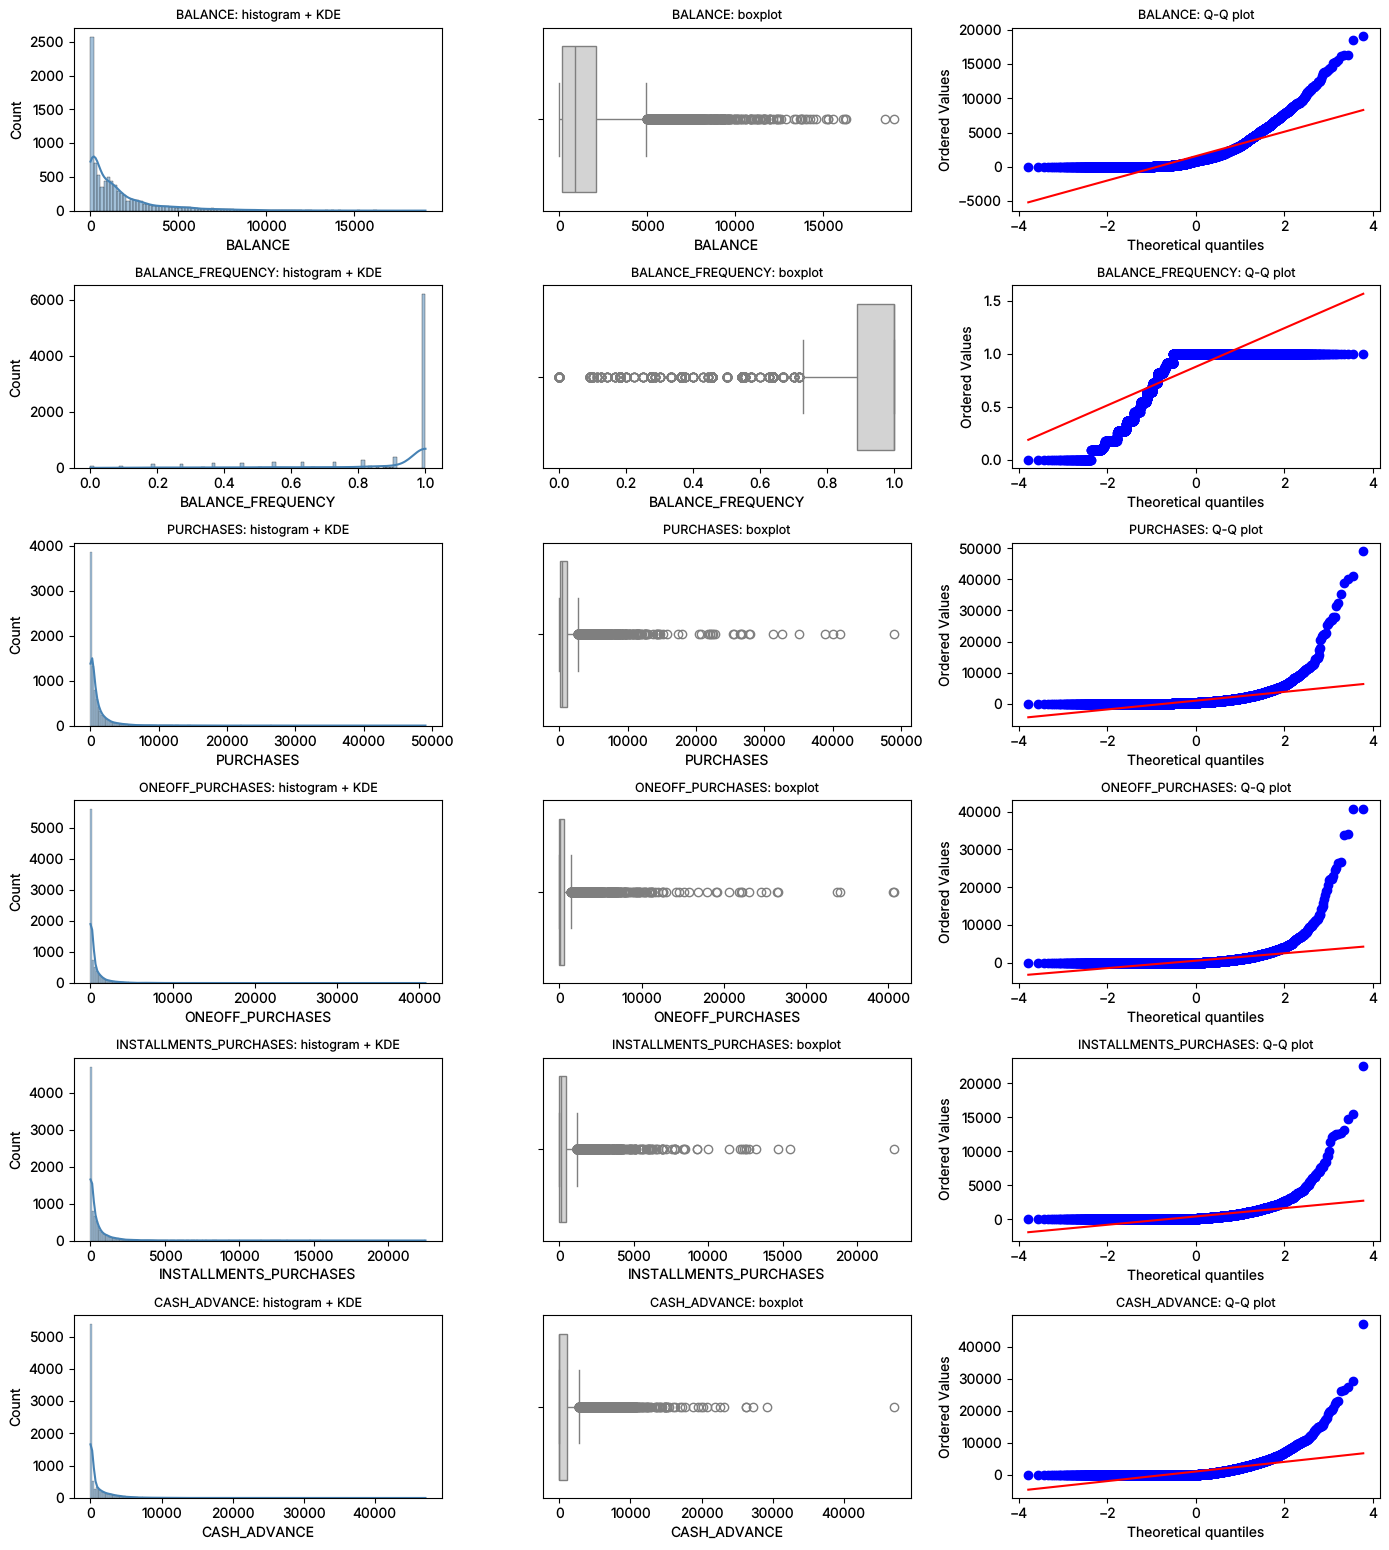

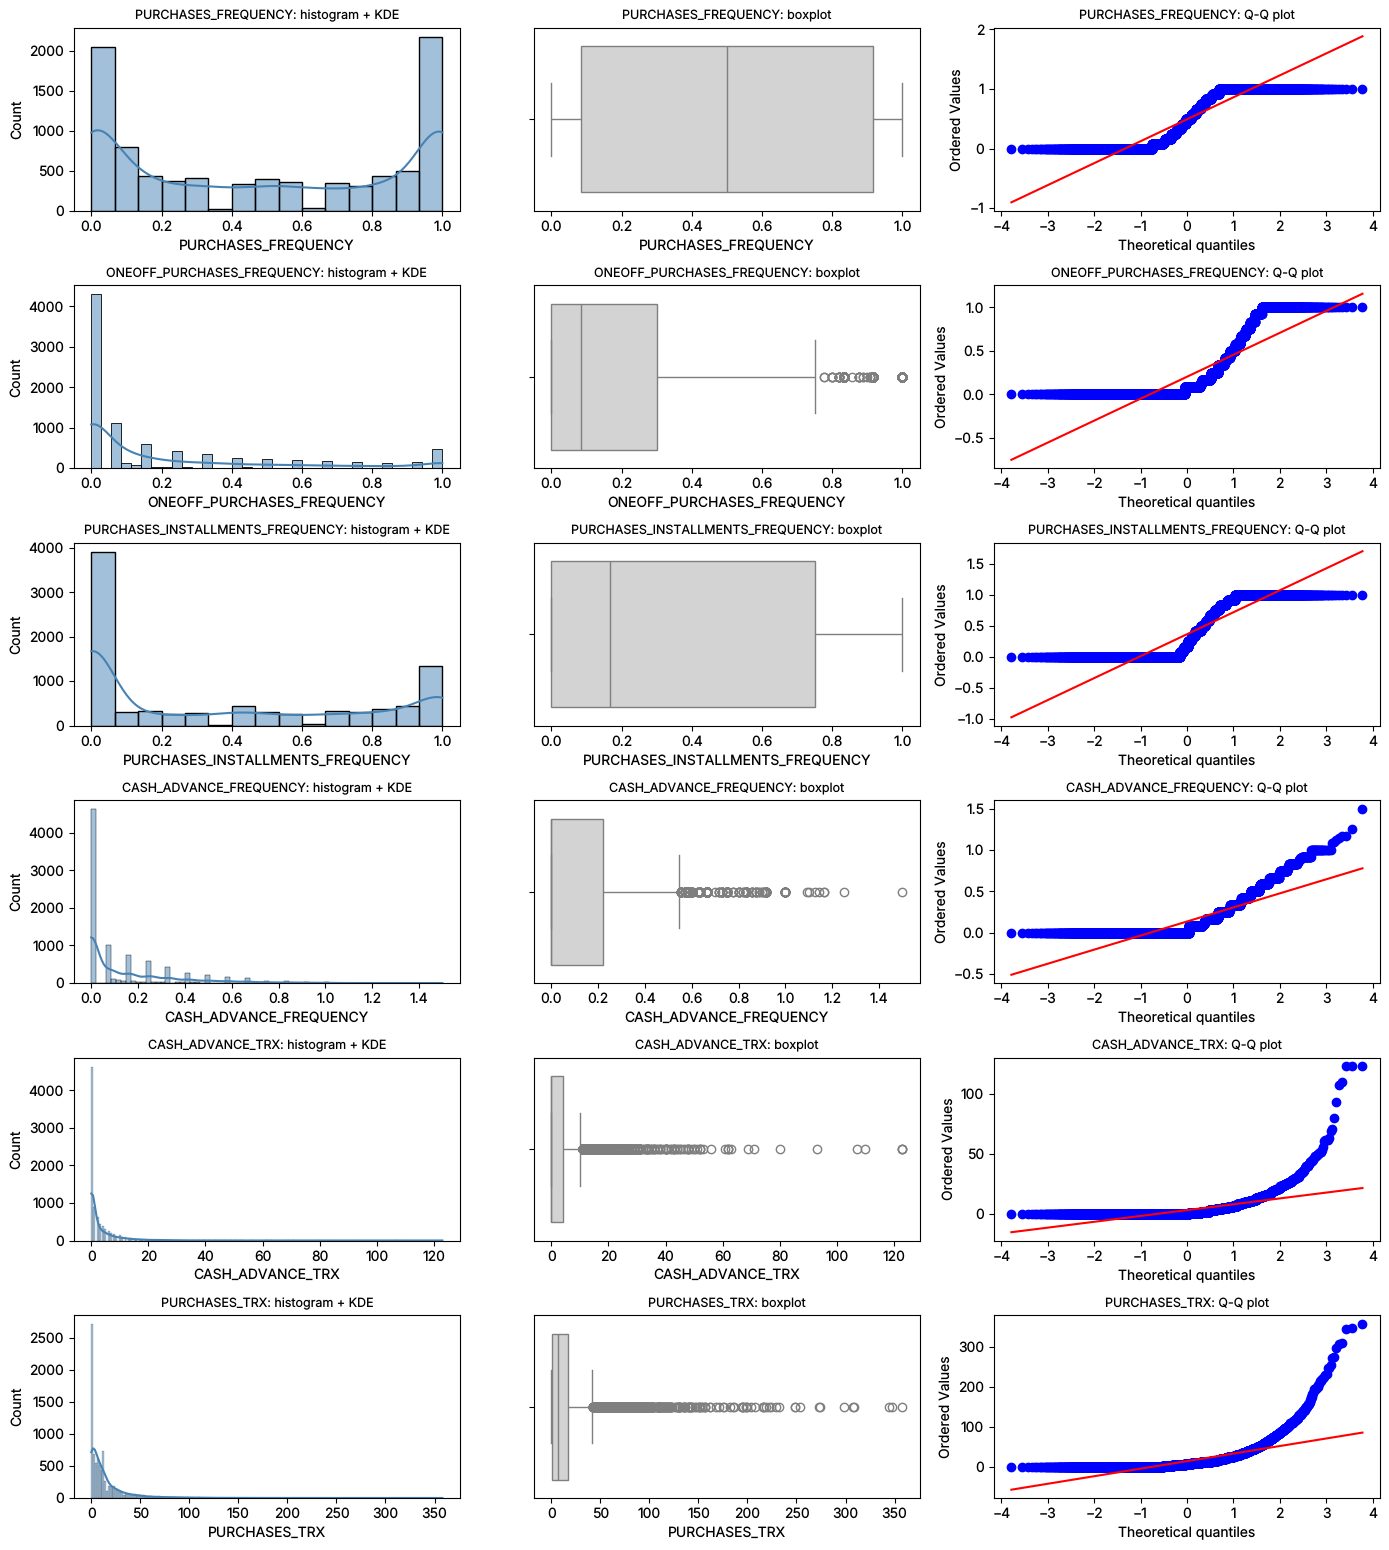

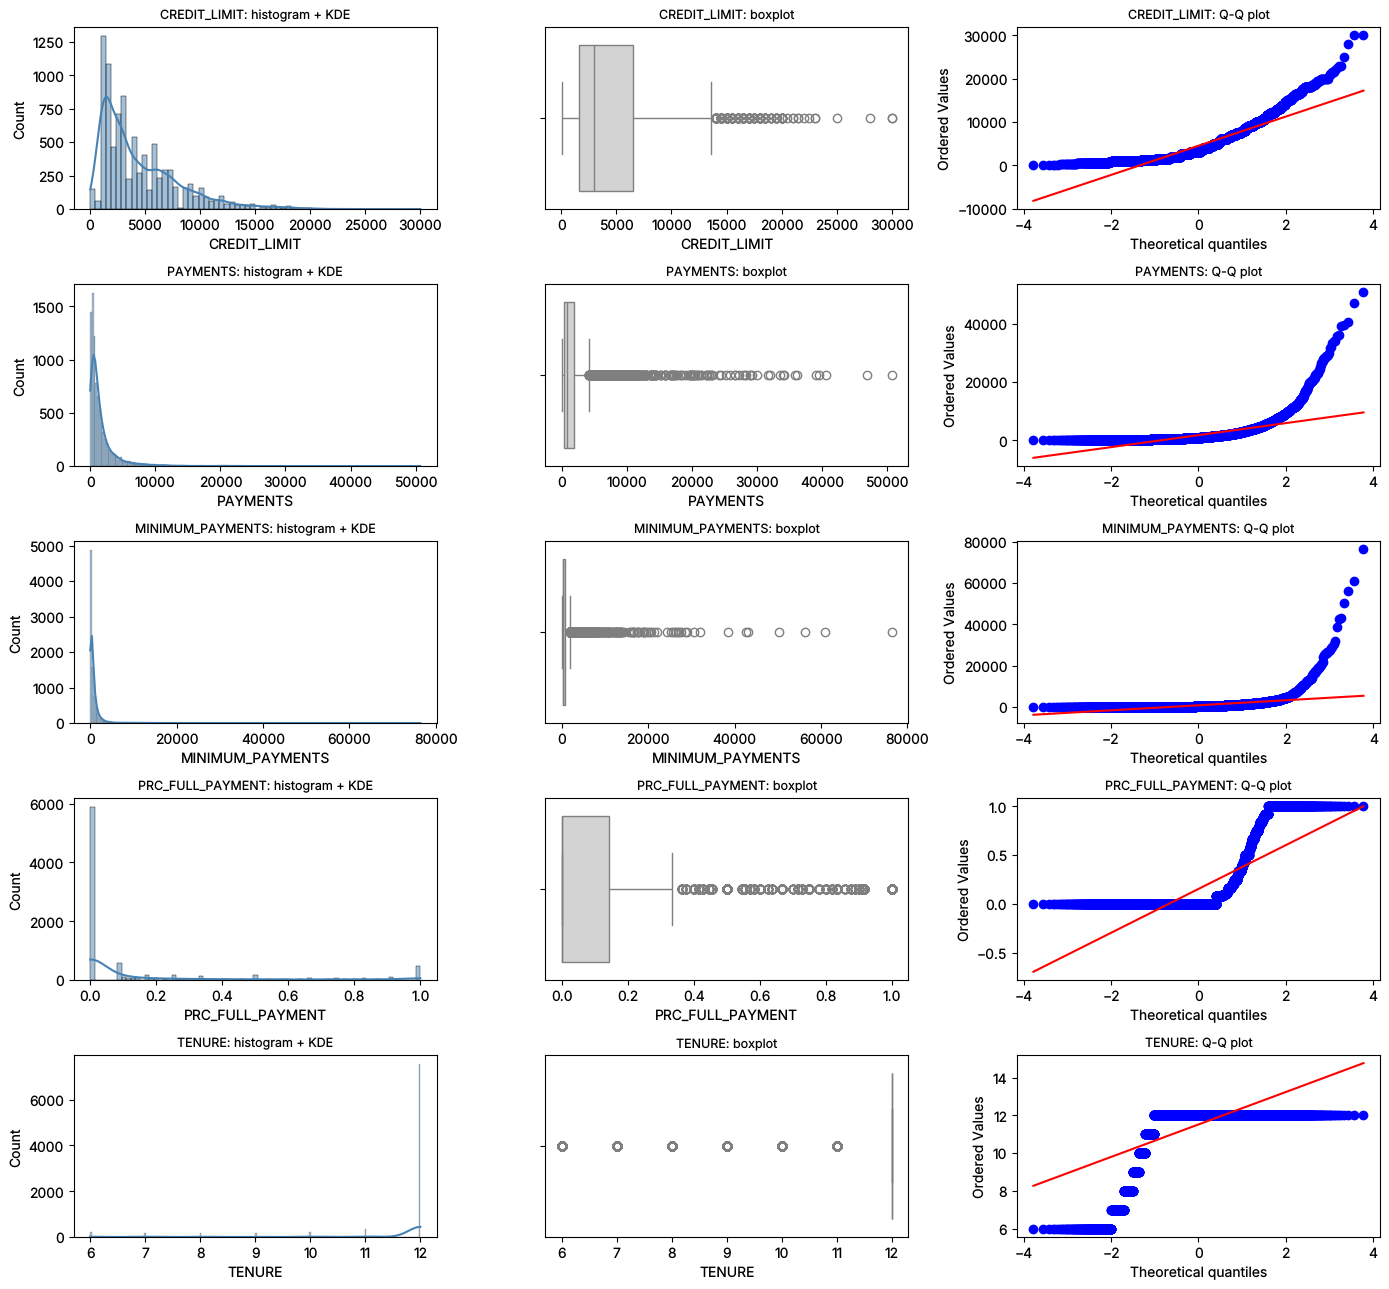

In [8]:
import matplotlib.pyplot as plt  # imported here because plotting starts in this cell
# Show plots inside the notebook (importing ydata-profiling earlier switches matplotlib to a no-display mode)
%matplotlib inline
import seaborn as sns            # nicer statistical plots on top of matplotlib

FIGURES_DIR = REPORTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def plot_univariate(feature_names: list[str], file_name: str) -> None:
    """One row per feature: histogram+KDE, boxplot, Q-Q plot."""
    fig, axes = plt.subplots(len(feature_names), 3, figsize=(14, 2.6 * len(feature_names)))
    for row, name in enumerate(feature_names):
        values = df[name].dropna()
        sns.histplot(values, kde=True, ax=axes[row, 0], color="steelblue")  # bars + smooth KDE line
        axes[row, 0].set_title(f"{name}: histogram + KDE", fontsize=9)
        sns.boxplot(x=values, ax=axes[row, 1], color="lightgray")           # box = middle 50%, dots = outliers
        axes[row, 1].set_title(f"{name}: boxplot", fontsize=9)
        stats.probplot(values, dist="norm", plot=axes[row, 2])              # Q-Q plot against a normal curve
        axes[row, 2].set_title(f"{name}: Q-Q plot", fontsize=9)
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / file_name, dpi=110)
    plt.show()


# Three batches of features (6, 6, 5) so each figure stays readable
for batch_number, start in enumerate(range(0, len(features), 6), start=1):
    plot_univariate(features[start:start + 6], f"univariate_{batch_number}.png")

### Normality tests

A *normality test* asks: "could this column plausibly have come from a normal (bell curve) distribution?" Each test gives a **p-value**. If p is below 0.05 (our alpha, the cut-off for "surprising"), we reject normality.

- **Shapiro-Wilk** is a strong test, but it becomes overly strict on large samples: with thousands of rows it flags even tiny, harmless differences from a bell curve. That is why we run it on a random sample of at most 5,000 rows.
- **D'Agostino K-squared** (`scipy.stats.normaltest`) combines skewness and kurtosis into one test. We run it on the full data.

**What this cell does:** Runs both normality tests on every feature and puts the results in one table with a yes/no column.  
**What to look for:** The `normal_at_0.05` column, and how small the p-values are.  
**What the output means:** p-values below 0.05 mean the test rejects normality. We call a feature normal only if it passes both tests. A p-value printed as 0.00e+00 just means it is smaller than the computer can store. (SciPy warns that Shapiro p-values are approximate above 5,000 rows, which is one more reason we sample.)

In [9]:
rows = []
for name in features:
    values = df[name].dropna()
    sample = values.sample(n=min(5000, len(values)), random_state=42)  # fixed seed so results repeat
    shapiro_p = stats.shapiro(sample).pvalue          # Shapiro-Wilk on the sample
    dagostino_p = stats.normaltest(values).pvalue     # D'Agostino K-squared on all rows
    rows.append({
        "feature": name,
        "shapiro_p (sample)": shapiro_p,
        "dagostino_p (full)": dagostino_p,
        # one-liner: "yes" only if BOTH p-values are above alpha (0.05), otherwise "no"
        "normal_at_0.05": "yes" if min(shapiro_p, dagostino_p) > 0.05 else "no",
    })

normality_table = pd.DataFrame(rows).set_index("feature")
normality_table.style.format({"shapiro_p (sample)": "{:.2e}", "dagostino_p (full)": "{:.2e}"})  # sci notation for tiny p

,shapiro_p (sample),dagostino_p (full),normal_at_0.05
feature,,,
BALANCE,9.39e-68,0.00e+00,no
BALANCE_FREQUENCY,9.18e-76,0.00e+00,no
PURCHASES,2.87e-82,0.00e+00,no
ONEOFF_PURCHASES,4.35e-86,0.00e+00,no
INSTALLMENTS_PURCHASES,8.93e-82,0.00e+00,no
CASH_ADVANCE,7.10e-79,0.00e+00,no
PURCHASES_FREQUENCY,2.18e-57,0.00e+00,no
ONEOFF_PURCHASES_FREQUENCY,9.83e-69,0.00e+00,no
PURCHASES_INSTALLMENTS_FREQUENCY,2.82e-62,0.00e+00,no


**What this cell does:** Counts how many features are strongly right-skewed and lists the ones that are not.  
**What to look for:** The number of features with skewness above 1, and which features are the exceptions.  
**What the output means:** This confirms or corrects our expectation that credit card amounts are right-skewed, and it tells us which columns need a transform in Step 5.

In [10]:
strongly_right_skewed = shape_table[shape_table["skewness"] > 1].index.tolist()
others = shape_table[shape_table["skewness"] <= 1]
print(f"{len(strongly_right_skewed)=} of {len(features)}")
print(f"{strongly_right_skewed=}")
print("Not strongly right-skewed:")
print(others.to_string())
print(f"{(normality_table['normal_at_0.05'] == 'yes').sum()=} features pass both normality tests")

len(strongly_right_skewed)=13 of 17
strongly_right_skewed=['MINIMUM_PAYMENTS', 'ONEOFF_PURCHASES', 'PURCHASES', 'INSTALLMENTS_PURCHASES', 'PAYMENTS', 'CASH_ADVANCE_TRX', 'CASH_ADVANCE', 'PURCHASES_TRX', 'BALANCE', 'PRC_FULL_PAYMENT', 'CASH_ADVANCE_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'CREDIT_LIMIT']
Not strongly right-skewed:
                                  skewness  excess_kurtosis
PURCHASES_INSTALLMENTS_FREQUENCY      0.51            -1.40
PURCHASES_FREQUENCY                   0.06            -1.64
BALANCE_FREQUENCY                    -2.02             3.09
TENURE                               -2.94             7.69
(normality_table['normal_at_0.05'] == 'yes').sum()=np.int64(0) features pass both normality tests


### What Step 2 tells us

- **Our expectation was mostly right, with an important exception.** 13 of 17 features have skewness above 1. All eight money amount columns and the count columns are strongly right-skewed (skewness from 2.4 for `BALANCE` up to 13.6 for `MINIMUM_PAYMENTS`), with huge excess kurtosis (up to 284), meaning a few very large customers stretch the tail.
- **The exceptions are the bounded columns.** `PURCHASES_FREQUENCY` (skew 0.06) and `PURCHASES_INSTALLMENTS_FREQUENCY` (0.51) are flat, with piles at 0 and 1, so they are not right-skewed. `BALANCE_FREQUENCY` (-2.0) and `TENURE` (-2.9) are *left*-skewed because most customers sit at the maximum (1.0 and 12 months). A log transform would be the wrong tool for these.
- **No feature is normal.** Zero of 17 pass both tests. Shapiro-Wilk p-values (on 5,000 sampled rows) are all below 1e-55 and the D'Agostino p-values underflow to 0. Because the skewness and kurtosis are so large, this verdict does not depend on Shapiro being too strict: even a lenient test would reject. Even `PURCHASES_FREQUENCY`, with skewness near 0, fails because its shape is flat, not bell-shaped.
- **What this means for KMeans.** KMeans does not need normal data. The real problem is scale and extremes: it uses straight-line distance, so a feature in the tens of thousands of dollars would swamp one measured from 0 to 1, and a few giant customers would pull the cluster centres. So we will log-transform the skewed *amount and count* columns (Step 5), leave the bounded 0 to 1 columns alone, and then put everything on one scale.

---
## Step 3: Correlation and multicollinearity

*Correlation* measures how strongly two columns move together (from -1 to +1). *Multicollinearity* means several features carry nearly the same information.

We use **Spearman** correlation instead of Pearson. Pearson measures straight-line relationships and is thrown off by extreme values; Spearman compares only the *ranks* (who is first, second, third), so skew and outliers hardly affect it.

**What this cell does:** Computes the Spearman correlation between every pair of features and draws an annotated heatmap.  
**What to look for:** Dark red blocks (strong positive) and dark blue (strong negative). Look for groups of features that form a block.  
**What the output means:** Each cell shows how closely two features rank customers the same way. Values near +1 mean one feature adds almost no new information beyond the other.

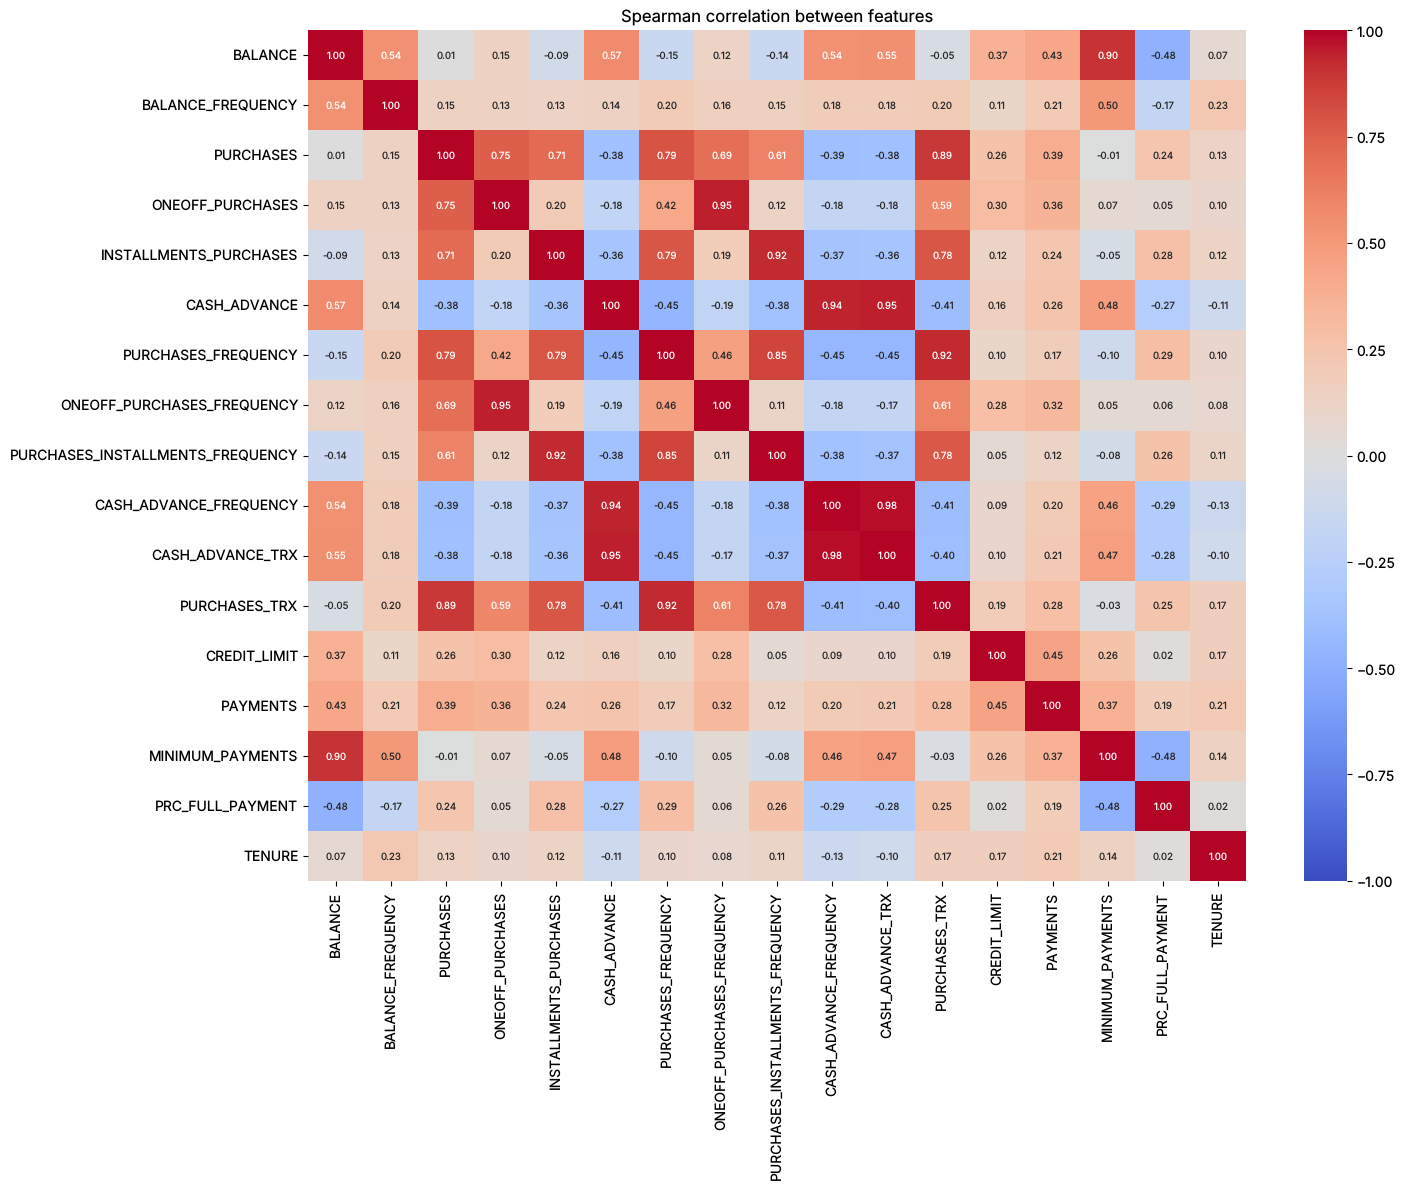

In [11]:
spearman = df[features].corr(method="spearman")  # rank-based correlation, robust to skew

plt.figure(figsize=(15, 12))
sns.heatmap(spearman, annot=True, fmt=".2f", annot_kws={"size": 7}, cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Spearman correlation between features")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "spearman_heatmap.png", dpi=110)
plt.show()

**What this cell does:** Lists every pair of different features with an absolute Spearman correlation above 0.8.  
**What to look for:** Which pairs appear and how many times each feature shows up.  
**What the output means:** These are the redundant pairs. A feature that appears in many pairs is a good candidate to drop or to keep as the single representative of its group.

In [12]:
import numpy as np  # needed to keep only the upper triangle so each pair is listed once

upper_triangle = spearman.where(np.triu(np.ones(spearman.shape, dtype=bool), k=1))  # k=1 skips the diagonal
high_pairs = (
    upper_triangle.stack()                                  # turn the matrix into (feature_a, feature_b) -> value
    .rename_axis(["feature_a", "feature_b"])               # name the two index levels
    .reset_index(name="spearman")                           # turn them into columns
    .loc[lambda pairs: pairs["spearman"].abs() > 0.8]       # keep strong pairs only
    .sort_values("spearman", key=abs, ascending=False)
    .round(2)
)
display(high_pairs.reset_index(drop=True))
print("How often each feature appears in a high pair:")
print(pd.concat([high_pairs["feature_a"], high_pairs["feature_b"]]).value_counts().to_string())

,feature_a,feature_b,spearman
0,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,0.98
1,ONEOFF_PURCHASES,ONEOFF_PURCHASES_FREQUENCY,0.95
2,CASH_ADVANCE,CASH_ADVANCE_TRX,0.95
3,CASH_ADVANCE,CASH_ADVANCE_FREQUENCY,0.94
4,PURCHASES_FREQUENCY,PURCHASES_TRX,0.92
5,INSTALLMENTS_PURCHASES,PURCHASES_INSTALLMENTS_FREQUENCY,0.92
6,BALANCE,MINIMUM_PAYMENTS,0.90
7,PURCHASES,PURCHASES_TRX,0.89
8,PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,0.85


How often each feature appears in a high pair:
CASH_ADVANCE_FREQUENCY              2
CASH_ADVANCE                        2
PURCHASES_FREQUENCY                 2
CASH_ADVANCE_TRX                    2
PURCHASES_INSTALLMENTS_FREQUENCY    2
PURCHASES_TRX                       2
ONEOFF_PURCHASES                    1
INSTALLMENTS_PURCHASES              1
PURCHASES                           1
BALANCE                             1
ONEOFF_PURCHASES_FREQUENCY          1
MINIMUM_PAYMENTS                    1


### Decision: which features to keep

Nine pairs are above 0.8. They fall into clear families. Our rule: when two features are the *same quantity counted differently* (an amount versus a count or a frequency), keep one and drop the others, so one behaviour does not get counted two or three times in the distance.

| Pair (Spearman) | Decision | Reason |
|---|---|---|
| `CASH_ADVANCE_FREQUENCY` and `CASH_ADVANCE_TRX` (0.98), `CASH_ADVANCE` with each (0.94, 0.95) | **Keep `CASH_ADVANCE`, drop the other two** | Three versions of "how much cash does this customer borrow". The amount is the one with direct business meaning (money borrowed at a high rate). |
| `PURCHASES` and `PURCHASES_TRX` (0.89), `PURCHASES_FREQUENCY` and `PURCHASES_TRX` (0.92) | **Drop `PURCHASES` and `PURCHASES_TRX`, keep `PURCHASES_FREQUENCY`** | `PURCHASES` is (almost exactly) one-off plus installments, which we keep separately, so it adds no new information. The transaction count says what the frequency already says. |
| `ONEOFF_PURCHASES` and `ONEOFF_PURCHASES_FREQUENCY` (0.95) | **Keep the amount, drop the frequency** | Same behaviour, and overall purchase frequency is kept through `PURCHASES_FREQUENCY`. |
| `INSTALLMENTS_PURCHASES` and `PURCHASES_INSTALLMENTS_FREQUENCY` (0.92), `PURCHASES_FREQUENCY` and `PURCHASES_INSTALLMENTS_FREQUENCY` (0.85) | **Keep the amount, drop the frequency** | Same reasoning, and this also resolves the 0.85 pair. |
| `BALANCE` and `MINIMUM_PAYMENTS` (0.90) | **Keep both** | This is the one exception. They are different things (what is owed versus the smallest payment due), 0.90 is close to our line, and the minimum payment helps show who under-pays. We will check in notebook 03 that dropping it does not change the clusters. |

**Result:** we drop 6 features (`PURCHASES`, `PURCHASES_TRX`, `CASH_ADVANCE_TRX`, `CASH_ADVANCE_FREQUENCY`, `ONEOFF_PURCHASES_FREQUENCY`, `PURCHASES_INSTALLMENTS_FREQUENCY`) and keep 11 for clustering. In Step 8 we still show the dropped columns when we describe each cluster, because they are useful for explaining it in business terms.

**What this cell does:** Records the six dropped features in one place and checks which strong pairs remain among the 11 kept features.  
**What to look for:** Only the BALANCE and MINIMUM_PAYMENTS pair should remain above 0.8.  
**What the output means:** This proves the drop list does what we claimed, instead of trusting the table above by eye.

In [13]:
FEATURES_TO_DROP = [
    "PURCHASES", "PURCHASES_TRX", "CASH_ADVANCE_TRX",
    "CASH_ADVANCE_FREQUENCY", "ONEOFF_PURCHASES_FREQUENCY", "PURCHASES_INSTALLMENTS_FREQUENCY",
]
kept_features = [name for name in features if name not in FEATURES_TO_DROP]
print(f"{len(kept_features)=}")

kept_pairs = high_pairs[high_pairs["feature_a"].isin(kept_features) & high_pairs["feature_b"].isin(kept_features)]
print("Strong pairs left among kept features:")
print(kept_pairs.to_string(index=False))

len(kept_features)=11
Strong pairs left among kept features:
feature_a        feature_b  spearman
  BALANCE MINIMUM_PAYMENTS       0.9


---
## Step 4: Missing values and outliers

### Missing values: the options

1. **Drop the rows.** Simple, but we lose customers (and the customers who are missing may be a special group, which would bias the result).
2. **Median imputation.** Fill each blank with the column's median (the middle value). Robust to extreme values, which matters because these columns are heavily skewed. Fast and easy to explain.
3. **Model-based imputation** (for example KNN or iterative imputation). Predicts each blank from the other columns. More flexible, but slower, harder to explain, and not worth it when only 3.5% is missing in one column.

First we check *why* the values are missing, because the reason affects the choice.

**What this cell does:** Looks at the customers whose MINIMUM_PAYMENTS or CREDIT_LIMIT is missing, and compares their other columns with everyone else.  
**What to look for:** Whether the missing rows share a pattern, for example all having PAYMENTS equal to 0.  
**What the output means:** If blanks follow a pattern, they are not random. That tells us whether a plain median fill is a fair guess.

In [14]:
missing_min_payment = df["MINIMUM_PAYMENTS"].isna()
print(f"{missing_min_payment.sum()=}")
print("PAYMENTS for customers missing MINIMUM_PAYMENTS:")
print(df.loc[missing_min_payment, "PAYMENTS"].describe().round(2).to_string())
print(f"{(df.loc[missing_min_payment, 'PAYMENTS'] == 0).mean()=:.3f}")
print(f"{(df.loc[~missing_min_payment, 'PAYMENTS'] == 0).sum()=}  (zero payments among rows that have a minimum payment)")
print("Row missing CREDIT_LIMIT:")
df[df["CREDIT_LIMIT"].isna()].T

missing_min_payment.sum()=np.int64(313)
PAYMENTS for customers missing MINIMUM_PAYMENTS:
count      313.00
mean       322.29
std       1996.66
min          0.00
25%          0.00
50%          0.00
75%          0.00
max      29272.49
(df.loc[missing_min_payment, 'PAYMENTS'] == 0).mean()=0.767
(df.loc[~missing_min_payment, 'PAYMENTS'] == 0).sum()=np.int64(0)  (zero payments among rows that have a minimum payment)
Row missing CREDIT_LIMIT:


,5203
CUST_ID,C15349
BALANCE,18.400472
BALANCE_FREQUENCY,0.166667
PURCHASES,0.0
ONEOFF_PURCHASES,0.0
INSTALLMENTS_PURCHASES,0.0
CASH_ADVANCE,186.853063
PURCHASES_FREQUENCY,0.0
ONEOFF_PURCHASES_FREQUENCY,0.0
PURCHASES_INSTALLMENTS_FREQUENCY,0.0


### What the missing values tell us

- 313 customers lack `MINIMUM_PAYMENTS`, and **77% of them (240) made exactly zero payments**. Among customers who do have a minimum payment, none have zero payments. So the blank is not random: it most likely means "no payment was due or made". (We did not look for a pattern in the remaining 73.)
- `CREDIT_LIMIT` is missing for a single customer, with tiny balance and a tenure of 6 months. Nothing special.

### Decision: median imputation, inside a Pipeline

- **Why not drop rows?** We would lose 313 customers who are probably a real group (inactive on payments), and the clusters would not describe them.
- **Why not model-based?** For 3.5% of one column, KNN or iterative imputation adds complexity and run time with little gain, and is harder to explain to a business reader.
- **Why median?** Both columns are heavily skewed, so the mean (pulled up by giants) would be a poor guess. The median (about 312 for `MINIMUM_PAYMENTS`, 3,000 for `CREDIT_LIMIT`) is a typical value.
- **Honest limitation:** the median is not perfect for the 240 zero-payment customers, for whom "0" may be more truthful. We will run a quick check in notebook 03 (fill those with 0 instead) and report whether the clusters change.

**What this cell does:** Builds the imputation as a scikit-learn Pipeline and shows that it fills blanks the same way on brand new data.  
**What to look for:** Zero missing values after transform, and the learned medians. The new row should get the same median as the training data.  
**What the output means:** A Pipeline remembers what it learned (here, the medians) when fitted. Calling transform later on new customers fills blanks using the training medians, never the new data's own, which avoids data leakage (information from outside the training data sneaking in). Notebook 02 reuses this inside the full preprocessing pipeline.

In [15]:
from sklearn.impute import SimpleImputer  # SimpleImputer fills blank values (here with the median)
from sklearn.pipeline import Pipeline  # Pipeline chains steps so they run the same way on any data

imputation_pipeline = Pipeline([("median_imputer", SimpleImputer(strategy="median"))]).set_output(transform="pandas")
imputed = imputation_pipeline.fit_transform(df[features])  # learn medians, then fill blanks
print(f"{imputed.isna().sum().sum()=}")
print("Learned medians for the two columns that had blanks:")
print(imputation_pipeline.named_steps["median_imputer"].statistics_[[features.index("CREDIT_LIMIT"), features.index("MINIMUM_PAYMENTS")]])

# Simulate a new customer with blanks: the pipeline fills them with the TRAINING medians
new_customer = df[features].iloc[[0]].copy()
new_customer[["CREDIT_LIMIT", "MINIMUM_PAYMENTS"]] = np.nan
imputation_pipeline.transform(new_customer)[["CREDIT_LIMIT", "MINIMUM_PAYMENTS"]]

imputed.isna().sum().sum()=np.int64(0)
Learned medians for the two columns that had blanks:
[3000.        312.343947]


,CREDIT_LIMIT,MINIMUM_PAYMENTS
0,3000.0,312.343947


### Outliers with the IQR rule

The **IQR rule** (interquartile range) flags a value as an outlier if it is more than 1.5 times the IQR below the 25th percentile (Q1) or above the 75th percentile (Q3). The IQR is Q3 minus Q1, the spread of the middle half of customers. We only *flag* outliers. We do not remove them, because a high-value customer is exactly the kind of person a segmentation should find.

**What this cell does:** Flags outliers for every feature with the IQR rule and counts them.  
**What to look for:** Which features have the largest share of outliers, and how many features each customer is flagged on.  
**What the output means:** A feature with a large share of flagged rows has a heavy tail, not a few mistakes. A customer flagged on many features is consistently extreme, which looks like a real big spender or big borrower rather than a typo.

In [16]:
def iqr_outlier_flags(frame: pd.DataFrame) -> pd.DataFrame:
    """True where a value is outside [Q1 - 1.5*IQR, Q3 + 1.5*IQR], column by column."""
    q1 = frame.quantile(0.25)
    q3 = frame.quantile(0.75)
    iqr = q3 - q1
    return (frame < q1 - 1.5 * iqr) | (frame > q3 + 1.5 * iqr)  # broadcast comparison, one bound per column


outlier_flags = iqr_outlier_flags(df[features])
outlier_summary = pd.DataFrame({
    "outliers": outlier_flags.sum(),
    "percent": (outlier_flags.mean() * 100).round(1),
}).sort_values("outliers", ascending=False)
display(outlier_summary)

flags_per_customer = outlier_flags.sum(axis=1)  # on how many features is each customer flagged?
print(flags_per_customer.value_counts().sort_index().to_string())
print(f"{(flags_per_customer >= 5).sum()=} customers are flagged on 5 or more features")

,outliers,percent
BALANCE_FREQUENCY,1493,16.7
PRC_FULL_PAYMENT,1474,16.5
TENURE,1366,15.3
CASH_ADVANCE,1030,11.5
ONEOFF_PURCHASES,1013,11.3
INSTALLMENTS_PURCHASES,867,9.7
MINIMUM_PAYMENTS,841,9.4
PAYMENTS,808,9.0
PURCHASES,808,9.0
CASH_ADVANCE_TRX,804,9.0


0     2994
1     2549
2     1596
3      732
4      436
5      298
6      177
7      102
8       36
9       20
10       5
11       5
(flags_per_customer >= 5).sum()=np.int64(643) customers are flagged on 5 or more features


**What this cell does:** Shows the top 5 customers for purchases, cash advance and balance, together with simple ratios that would reveal data errors.  
**What to look for:** Do the numbers make sense together? For example, purchases that match the number of transactions, a high credit limit for big spenders, and payments in a similar range.  
**What the output means:** Data errors tend to look inconsistent (a huge purchase total with 0 transactions, a balance far above the credit limit for no reason). Real high-value customers look internally consistent.

In [17]:
inspection_columns = ["BALANCE", "PURCHASES", "PURCHASES_TRX", "CASH_ADVANCE", "CASH_ADVANCE_TRX", "CREDIT_LIMIT", "PAYMENTS", "TENURE"]
for column in ["PURCHASES", "CASH_ADVANCE", "BALANCE"]:
    top = df.nlargest(5, column)[inspection_columns].copy()
    top["avg_purchase_size"] = (top["PURCHASES"] / top["PURCHASES_TRX"]).round(0)   # money per purchase
    top["purchases_vs_limit"] = (top["PURCHASES"] / top["CREDIT_LIMIT"]).round(1)   # spend as a multiple of the limit
    print(f"Top 5 by {column}")
    display(top.round(0))

Top 5 by PURCHASES


,BALANCE,PURCHASES,PURCHASES_TRX,CASH_ADVANCE,CASH_ADVANCE_TRX,CREDIT_LIMIT,PAYMENTS,TENURE,avg_purchase_size,purchases_vs_limit
550,11548.0,49040.0,101,558.0,1,22500.0,46931.0,12,486.0,2.0
501,13479.0,41050.0,157,0.0,0,17000.0,36067.0,12,261.0,2.0
1256,4011.0,40041.0,358,0.0,0,18000.0,33995.0,12,112.0,2.0
1604,3392.0,38903.0,195,0.0,0,18000.0,35844.0,12,200.0,2.0
3937,2998.0,35131.0,344,0.0,0,12000.0,28897.0,12,102.0,3.0


Top 5 by CASH_ADVANCE


,BALANCE,PURCHASES,PURCHASES_TRX,CASH_ADVANCE,CASH_ADVANCE_TRX,CREDIT_LIMIT,PAYMENTS,TENURE,avg_purchase_size,purchases_vs_limit
2159,10905.0,432.0,21,47137.0,123,19600.0,39049.0,12,21.0,0.0
1059,8823.0,3719.0,61,29282.0,26,15500.0,28151.0,12,61.0,0.0
71,2990.0,4523.0,33,27296.0,27,7000.0,28233.0,12,137.0,1.0
7254,4530.0,1751.0,36,26269.0,10,8500.0,25204.0,12,49.0,0.0
7645,7081.0,0.0,0,26194.0,69,9000.0,20191.0,11,NaN,0.0


Top 5 by BALANCE


,BALANCE,PURCHASES,PURCHASES_TRX,CASH_ADVANCE,CASH_ADVANCE_TRX,CREDIT_LIMIT,PAYMENTS,TENURE,avg_purchase_size,purchases_vs_limit
138,19043.0,22010.0,216,0.0,0,18000.0,23019.0,12,102.0,1.0
4140,18496.0,5288.0,76,0.0,0,22000.0,4246.0,12,70.0,0.0
5488,16305.0,1771.0,9,7424.0,13,19000.0,5338.0,12,197.0,0.0
6629,16259.0,5025.0,143,329.0,2,18000.0,4987.0,12,35.0,0.0
5281,16116.0,685.0,15,4354.0,15,18000.0,3546.0,12,46.0,0.0


**What this cell does:** Runs simple consistency checks that would point to data errors.  
**What to look for:** Counts that are zero or tiny. Large counts mean a rule in the data we do not understand yet.  
**What the output means:** Each line is a rule that clean data should follow. Few violations means the extreme values are probably real behaviour, not mistakes.

In [18]:
frequency_columns = [column for column in features if column.endswith("_FREQUENCY") or column == "PRC_FULL_PAYMENT"]
checks = {
    "negative values anywhere": int((df[features] < 0).sum().sum()),
    "ratio columns outside 0 to 1": int(((df[frequency_columns] < 0) | (df[frequency_columns] > 1)).sum().sum()),
    "purchases > 0 but 0 purchase transactions": int(((df["PURCHASES"] > 0) & (df["PURCHASES_TRX"] == 0)).sum()),
    "cash advance > 0 but 0 cash advance transactions": int(((df["CASH_ADVANCE"] > 0) & (df["CASH_ADVANCE_TRX"] == 0)).sum()),
    "one-off purchases above total purchases": int((df["ONEOFF_PURCHASES"] > df["PURCHASES"] + 0.01).sum()),
    "balance above credit limit": int((df["BALANCE"] > df["CREDIT_LIMIT"]).sum()),
    "purchases above 5x credit limit": int((df["PURCHASES"] > 5 * df["CREDIT_LIMIT"]).sum()),
    "minimum payment above payments": int((df["MINIMUM_PAYMENTS"] > df["PAYMENTS"]).sum()),
}
pd.Series(checks, name="rows").to_frame()

,rows
negative values anywhere,0
ratio columns outside 0 to 1,8
purchases > 0 but 0 purchase transactions,3
cash advance > 0 but 0 cash advance transactions,0
one-off purchases above total purchases,3
balance above credit limit,227
purchases above 5x credit limit,9
minimum payment above payments,2365


### What the outliers tell us

- **The IQR rule flags a lot, and that is itself a finding.** Between 3% and 12% of customers are flagged on each money column, because these columns are heavy-tailed. 643 customers (7.2%) are flagged on five or more features at once. Being extreme on many features together points to genuinely different customers, not typos.
- **The bounded columns are flagged for the wrong reason.** `BALANCE_FREQUENCY` (16.7%), `PRC_FULL_PAYMENT` (16.5%) and `TENURE` (15.3%) show many "outliers" only because most customers sit at one value (1.0, 0, 12), which makes the IQR near zero. The IQR rule is not meaningful for these three, so we ignore their flags.
- **The top customers look real.**
  - *Top spenders:* purchases of 35,000 to 49,000 over 100 to 358 transactions (typical purchase about 100 to 490), credit limits of 12,000 to 22,500, and payments close to the purchase total. These are heavy users who pay what they spend.
  - *Top cash advance users:* up to 47,137 in cash over 123 transactions, with payments of 39,000. Large but internally consistent.
  - *Top balances:* about 16,000 to 19,000 on credit limits of 18,000 to 22,000. Plausible.
- **Real data errors exist but are tiny.** Out of 8,950 rows: 8 rows have `CASH_ADVANCE_FREQUENCY` above 1 (a share cannot exceed 100%), 3 have purchases but zero purchase transactions, and 3 have one-off purchases above total purchases. That is about 14 rows (0.2%), too few to matter. 227 customers (2.5%) have a balance above their credit limit and 9 spent more than 5 times their limit over 6 months while repaying a lot; both are plausible when someone repays and spends again.
- **A caution about `MINIMUM_PAYMENTS` above `PAYMENTS`.** This happens for 2,365 customers (26%). It could mean customers who pay less than the minimum due, or it could be a difference in how the two columns are measured (we have no data dictionary). We treat it as behaviour, not error, but we will not build a business claim on it.

### Decision

**Keep every row.** We do not remove outliers: the high-value customers are the segment a bank most wants to find. Instead, the log transform in Step 5 will tame their pull on the distances, and the 14 inconsistent rows are left as they are.

---
# Part 2: Preprocessing and dimensionality reduction
*Steps 5 and 6: transforms, the preprocessing pipeline, PCA. Same content as `notebooks/02_preprocessing.ipynb`.*

In notebook 01 we found that the money columns are heavily right-skewed, that some features repeat each other, and that a few values are missing. Here we fix those problems so KMeans can work well.

**Plan**
1. Keep the 11 features chosen in notebook 01 and compare several ways of transforming and scaling them (Step 5).
2. Build the chosen option as one scikit-learn Pipeline, so the exact same steps apply to any new customer.
3. Use PCA to look at the structure of the data (Step 6).

Every code cell has a short note above it with three lines. Imports sit inside the cells that first use them.

## Step 5: Preprocessing

**What this cell does:** Loads the data, drops the ID and the six redundant features from notebook 01, and fills the few blanks with the median (inside a Pipeline step, so it is reusable).  
**What to look for:** The shape (8,950 rows by 11 columns) and zero missing values after imputation.  
**What the output means:** These 11 columns are the starting point for every option we compare. Filling blanks first means the transformers below never see a missing value.

In [19]:
# Imported here so this step only loads the libraries when it runs
from pathlib import Path
import numpy as np  # numpy does fast maths on arrays of numbers
import pandas as pd  # pandas holds and summarises the customer table
from sklearn.impute import SimpleImputer  # SimpleImputer fills blank values (here with the median)


def find_project_root(start: Path = Path.cwd()) -> Path:
    """Walk up from the current folder until we see pyproject.toml (nbconvert runs inside notebooks/)."""
    return next(folder for folder in [start, *start.parents] if (folder / "pyproject.toml").exists())


ROOT = find_project_root()
PROCESSED_DIR = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Decided in notebook 01 (Step 3): each of these repeats information that another kept feature already holds
FEATURES_TO_DROP = [
    "PURCHASES", "PURCHASES_TRX", "CASH_ADVANCE_TRX",
    "CASH_ADVANCE_FREQUENCY", "ONEOFF_PURCHASES_FREQUENCY", "PURCHASES_INSTALLMENTS_FREQUENCY",
]

raw = pd.read_csv(ROOT / "data" / "raw" / "credit_card.csv").set_index("CUST_ID")  # keep the ID as the row label
all_features = raw.columns.tolist()  # the 17 original features
kept_features = [name for name in all_features if name not in FEATURES_TO_DROP]  # the 11 we cluster on
print(f"{raw.shape=}, {len(kept_features)=}")

# Median imputation (decision from notebook 01). We fit on all 17 columns so Step 8 can still describe dropped columns.
imputer = SimpleImputer(strategy="median").set_output(transform="pandas")
imputed_all = imputer.fit_transform(raw)           # learn medians and fill blanks
imputed = imputed_all[kept_features]               # the 11 clustering features, still in original units
print(f"{imputed.isna().sum().sum()=}")

raw.shape=(8950, 17), len(kept_features)=11
imputed.isna().sum().sum()=np.int64(0)


**What this cell does:** Decides which features get a log transform and checks that log1p is safe for them.  
**What to look for:** The two lists, and that the minimum of the log group is not negative.  
**What the output means:** `log1p(x)` means log(1 + x). It pulls in long right tails, and unlike a plain log it works when x is 0 (many customers have 0). It breaks for negative numbers, so we confirm there are none. The four bounded columns (shares from 0 to 1, and TENURE) stay as they are, as decided in notebook 01.

In [20]:
# Money and count columns: right-skewed, so log1p helps
log_features = [
    "BALANCE", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE",
    "CREDIT_LIMIT", "PAYMENTS", "MINIMUM_PAYMENTS",
]
# Bounded or near-constant columns: a log would be the wrong tool, we only scale them
plain_features = [name for name in kept_features if name not in log_features]
print(f"{log_features=}")
print(f"{plain_features=}")
print(f"{imputed[log_features].min().min()=}")  # must be >= 0 for log1p
assert imputed[log_features].min().min() >= 0

log_features=['BALANCE', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS']
plain_features=['BALANCE_FREQUENCY', 'PURCHASES_FREQUENCY', 'PRC_FULL_PAYMENT', 'TENURE']
imputed[log_features].min().min()=np.float64(0.0)


### Comparing four options

| Option | What it does |
|---|---|
| **A. StandardScaler alone** | Subtracts the mean and divides by the standard deviation, so each feature has mean 0 and spread 1 (a *z-score*). It does not change the shape, so skew stays. |
| **B. log1p, then StandardScaler** | Log-transforms the skewed columns first, then z-scores everything. |
| **C. QuantileTransformer** | Replaces each value with its rank, mapped onto a bell curve. Forces a normal shape no matter what. |
| **D. PowerTransformer (Yeo-Johnson)** | Finds the best power for each column to make it more symmetric. Works with zeros. |

We measure two things: **skewness** after the transform (closer to 0 is better) and **the largest absolute z-score** (how far the most extreme customer is from the average, in standard deviations). A KMeans distance is dominated by features with huge z-scores.

**What this cell does:** Applies the four options to the 11 features and builds one table of skewness per feature, plus two summary rows.  
**What to look for:** Column A should keep the original skew. Look at which option brings the most skewed features close to 0, and how large the biggest z-score stays.  
**What the output means:** Skewness near 0 means a symmetric shape. A max |z| of 20 means one customer is 20 standard deviations from average, which would drag a KMeans centre. Smaller is calmer.

In [21]:
from sklearn.preprocessing import FunctionTransformer, PowerTransformer, QuantileTransformer, StandardScaler  # the scalers and transformers we compare in this step

# Option B by hand here, to compare; the real pipeline is built further down
logged = imputed.copy()
logged[log_features] = np.log1p(logged[log_features])  # log(1 + x) on the skewed columns only

options = {
    "A: Standard only": StandardScaler().fit_transform(imputed),
    "B: log1p + Standard": StandardScaler().fit_transform(logged),
    "C: Quantile (normal)": QuantileTransformer(n_quantiles=1000, output_distribution="normal", random_state=0).fit_transform(imputed),
    "D: Yeo-Johnson": PowerTransformer(method="yeo-johnson").fit_transform(imputed),
}
option_frames = {name: pd.DataFrame(values, columns=kept_features, index=imputed.index) for name, values in options.items()}

# One-liner: for each option, skew() gives per-feature skewness; concat puts them side by side as columns
skew_table = pd.concat({name: frame.skew() for name, frame in option_frames.items()}, axis=1).round(2)
summary = pd.DataFrame({
    name: {
        "mean |skew|": frame.skew().abs().mean(),   # average lopsidedness across features
        "max |z-score|": frame.abs().max().max(),   # the single most extreme value anywhere
    }
    for name, frame in option_frames.items()
}).round(2)
display(skew_table)
display(summary)

,A: Standard only,B: log1p + Standard,C: Quantile (normal),D: Yeo-Johnson
BALANCE,2.39,-0.86,-0.77,-0.12
BALANCE_FREQUENCY,-2.02,-2.02,-0.94,-1.12
ONEOFF_PURCHASES,10.05,0.19,-0.01,0.12
INSTALLMENTS_PURCHASES,7.30,-0.02,-0.17,-0.01
CASH_ADVANCE,5.17,0.26,0.13,0.19
PURCHASES_FREQUENCY,0.06,0.06,-0.01,-0.04
CREDIT_LIMIT,1.52,-0.10,0.04,-0.01
PAYMENTS,5.91,-1.78,-1.54,0.12
MINIMUM_PAYMENTS,13.85,0.27,-0.02,-0.03
PRC_FULL_PAYMENT,1.94,1.94,0.97,0.96


,A: Standard only,B: log1p + Standard,C: Quantile (normal),D: Yeo-Johnson
mean |skew|,4.83,0.95,0.61,0.43
max |z-score|,32.39,5.08,5.20,5.87


**What this cell does:** Runs a quick KMeans (k=4) on each option as a sanity check and reports the silhouette score.  
**What to look for:** Whether any option is clearly better or worse, keeping in mind these scores come from different spaces.  
**What the output means:** Silhouette (from -1 to 1, higher means tighter, better-separated clusters) is not fully comparable across different transforms, so we use it only as a sanity check, not as the decision rule. The decision rests on skewness, extremes and interpretability.

In [22]:
from sklearn.cluster import KMeans  # KMeans groups customers around k centre points
from sklearn.metrics import silhouette_score  # silhouette score: how well separated the groups are (-1 to 1)

sanity = {}
for name, frame in option_frames.items():
    labels = KMeans(n_clusters=4, n_init=10, random_state=0).fit_predict(frame)
    # sample_size keeps this fast; random_state makes the sample repeatable
    sanity[name] = silhouette_score(frame, labels, sample_size=4000, random_state=0)
pd.Series(sanity, name="silhouette (k=4)").round(3).to_frame()

,silhouette (k=4)
A: Standard only,0.196
B: log1p + Standard,0.212
C: Quantile (normal),0.253
D: Yeo-Johnson,0.194


**What this cell does:** Draws before-and-after histograms for three of the most skewed features: raw, Option A, and Option B.  
**What to look for:** The raw and A histograms (same shape, one huge spike near 0), versus B (a spread-out shape).  
**What the output means:** This is the visual proof of what the skewness table says: scaling alone does not change the shape, a log transform does.

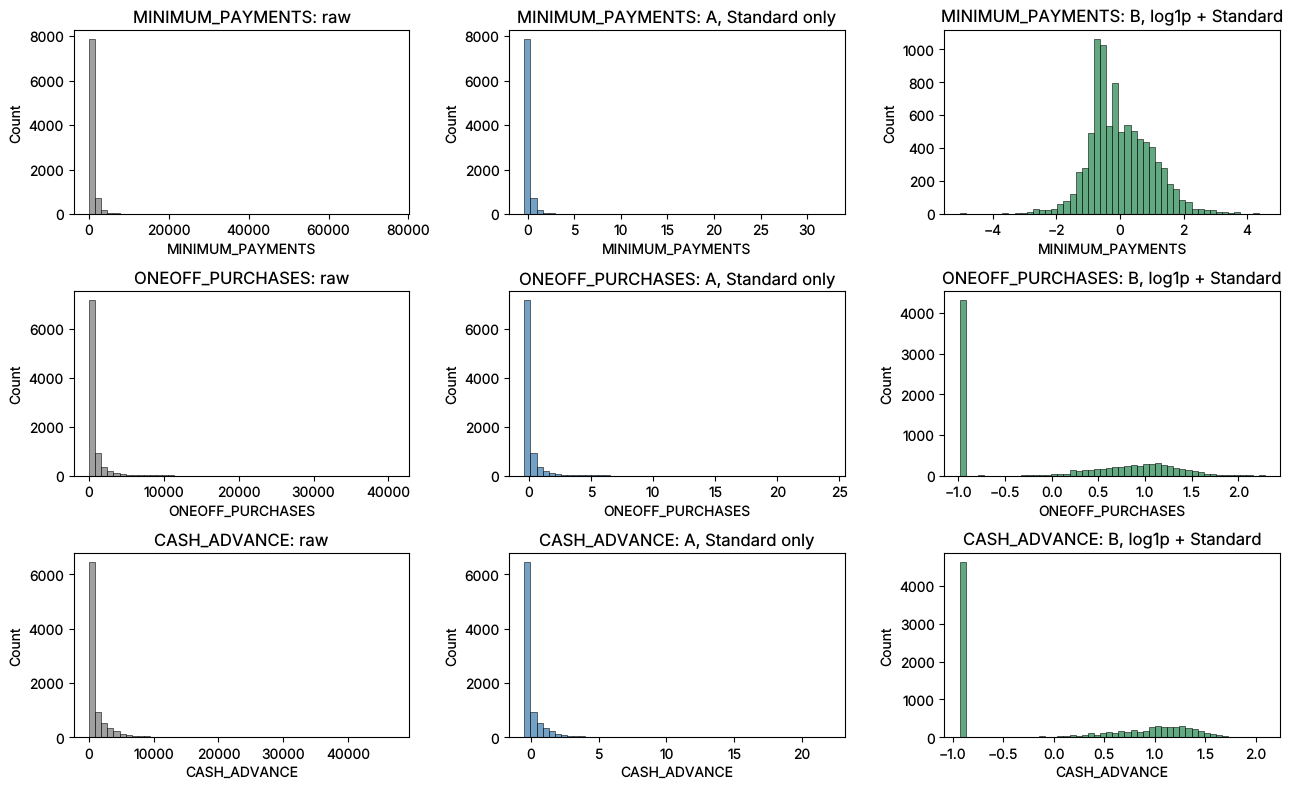

In [23]:
import matplotlib.pyplot as plt  # imported here because plotting starts in this cell
import seaborn as sns  # seaborn draws statistical plots on top of matplotlib

examples = ["MINIMUM_PAYMENTS", "ONEOFF_PURCHASES", "CASH_ADVANCE"]
fig, axes = plt.subplots(len(examples), 3, figsize=(13, 8))
for row, feature in enumerate(examples):
    sns.histplot(imputed[feature], bins=50, ax=axes[row, 0], color="gray")
    axes[row, 0].set_title(f"{feature}: raw")
    sns.histplot(option_frames["A: Standard only"][feature], bins=50, ax=axes[row, 1], color="steelblue")
    axes[row, 1].set_title(f"{feature}: A, Standard only")
    sns.histplot(option_frames["B: log1p + Standard"][feature], bins=50, ax=axes[row, 2], color="seagreen")
    axes[row, 2].set_title(f"{feature}: B, log1p + Standard")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "transform_comparison.png", dpi=110)
plt.show()

### What the comparison shows

| Option | Mean abs skew | Largest absolute z-score | Comment |
|---|---|---|---|
| A. Standard only | 4.83 | 32.4 | Shape unchanged. One customer sits 32 standard deviations out, so a handful of giants would steer KMeans. |
| **B. log1p + Standard** | **0.95** | **5.1** | Calmest extremes of all four. The seven log-transformed columns average about 0.5 skew. |
| C. Quantile (normal) | 0.61 | 5.2 | Looks good, but it ranks customers and *discards the size of the gaps*. It also smears the big pile of zeros into an artificial slope. |
| D. Yeo-Johnson | 0.43 | 5.9 | Lowest skew and a close second. Each column gets its own hidden power, which is harder to explain and to repeat by hand. |

**Reading the B column honestly.** The 0.95 average is held up by four columns we deliberately did not log: `TENURE` (-2.9), `BALANCE_FREQUENCY` (-2.0) and `PRC_FULL_PAYMENT` (1.9), which are bounded and have no better fix, and `PURCHASES_FREQUENCY`, which is already fine. `PAYMENTS` is slightly over-corrected (-1.8) and `BALANCE` a little (-0.9).

**The histograms add a warning that the skew number hides.** After `log1p`, `ONEOFF_PURCHASES` and `CASH_ADVANCE` look like a tall spike at the far left plus a bell curve. The spike is customers with exactly zero: 4,302 (48%) for one-off purchases, 4,628 (52%) for cash advance and 3,916 (44%) for installments. No transform removes this, and it should not be removed: "never uses this feature" is real behaviour and probably the main thing that separates the segments. It just means the skew number looks better than the shape really is.

(The sanity silhouette for C is the highest at 0.253. We do not treat that as a reason to choose it: the scores come from different spaces, and C's gain partly comes from squeezing the data into a tidier shape.)

### Decision: Option B (log1p, then StandardScaler)

- It has the **lowest extreme values** (largest |z| of 5.1), which is the property that protects KMeans from a few giants.
- It is **easy to explain and to repeat**: "we took the log of the money columns, then put everything on the same scale". A business reader can follow that, and a new customer can be treated with the same formula.
- It **keeps the zeros as a clear group** instead of smearing them.
- **Runner-up:** Yeo-Johnson (D). In notebook 03 we check that using D instead gives similar clusters.

Below we build B as a proper Pipeline.

**What this cell does:** Builds the final preprocessing as one scikit-learn Pipeline: impute, then (log1p + scale) for skewed columns and (scale) for bounded columns.  
**What to look for:** The output shape (8,950 by 11), column means near 0 and standard deviations near 1.  
**What the output means:** A Pipeline bundles every step. Fitted once, it can be saved and used on any new customer in exactly the same way: it reuses the training medians, the training scales, and applies the same log. ColumnTransformer sends different columns through different steps.

In [24]:
from sklearn.compose import ColumnTransformer  # ColumnTransformer sends different columns through different steps
from sklearn.pipeline import Pipeline  # Pipeline chains steps so they run the same way on any data

# Branch 1: log1p then z-score, for the skewed money columns
log_branch = Pipeline([
    ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scale", StandardScaler()),
])
# Branch 2: only z-score, for the bounded columns
plain_branch = Pipeline([("scale", StandardScaler())])

# Send each group of columns through its own branch; remainder="drop" throws away the 6 redundant columns
column_steps = ColumnTransformer(
    transformers=[("log", log_branch, log_features), ("plain", plain_branch, plain_features)],
    remainder="drop",
    verbose_feature_names_out=False,  # keep the plain column names
)

full_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),  # fills blanks using the training medians
    ("transform", column_steps),                   # log1p + scale, or scale only, depending on the column
]).set_output(transform="pandas")  # keep column names between steps

**What this cell does:** Fits the pipeline on the raw data and checks the result.  
**What to look for:** Shape (8,950, 11), no missing values, mean near 0 and standard deviation near 1 for every column.  
**What the output means:** This is the table KMeans will use. Each column is now on the same scale, so no single feature can dominate the distance.

In [25]:
scaled = full_pipeline.fit_transform(raw)  # learn medians, scales; return the scaled table
print(f"{scaled.shape=}, {scaled.isna().sum().sum()=}")
scaled.describe().loc[["mean", "std", "min", "max"]].round(2)

scaled.shape=(8950, 11), scaled.isna().sum().sum()=np.int64(0)


,BALANCE,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,BALANCE_FREQUENCY,PURCHASES_FREQUENCY,PRC_FULL_PAYMENT,TENURE
mean,0.00,0.00,0.00,0.00,-0.00,0.00,-0.00,0.00,-0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-3.06,-0.99,-1.09,-0.93,-5.08,-4.16,-5.04,-3.70,-1.22,-0.53,-4.12
max,1.83,2.28,2.16,2.09,2.70,2.64,4.55,0.52,1.27,2.89,0.36


**What this cell does:** Tests that the pipeline treats a brand new customer the same way, including a blank value.  
**What to look for:** The transformed row should have finite numbers and the same column order as the training table.  
**What the output means:** This proves reuse: in real life a new customer arrives with raw numbers and maybe a blank, and the saved pipeline can score them.

In [26]:
new_customer = raw.iloc[[0]].copy()
new_customer["MINIMUM_PAYMENTS"] = np.nan  # pretend this value is missing
print(full_pipeline.transform(new_customer).round(2).T.rename(columns={new_customer.index[0]: "scaled value"}))

CUST_ID                 scaled value
BALANCE                        -1.21
ONEOFF_PURCHASES               -0.99
INSTALLMENTS_PURCHASES          0.39
CASH_ADVANCE                   -0.93
CREDIT_LIMIT                   -1.45
PAYMENTS                       -0.82
MINIMUM_PAYMENTS               -0.14
BALANCE_FREQUENCY              -0.25
PURCHASES_FREQUENCY            -0.81
PRC_FULL_PAYMENT               -0.53
TENURE                          0.36


**What this cell does:** Saves the fitted pipeline, the scaled data and the imputed original-unit data to data/processed/.  
**What to look for:** That three files exist.  
**What the output means:** Notebook 03 loads the scaled table to cluster, and notebook 04 loads the original-unit table so explanations are in real dollars. Saving them means each notebook can run on its own.

In [27]:
import joblib  # imported here because this is the only place we save a model object

joblib.dump(full_pipeline, PROCESSED_DIR / "preprocessing_pipeline.joblib")   # the fitted recipe
scaled.to_csv(PROCESSED_DIR / "credit_card_scaled.csv")                       # for clustering
imputed_all.to_csv(PROCESSED_DIR / "credit_card_imputed_original_units.csv")  # all 17 columns, for profiling and SHAP
print(sorted(path.name for path in PROCESSED_DIR.glob("*") if path.name != ".gitkeep"))

['credit_card_imputed_original_units.csv', 'credit_card_scaled.csv', 'preprocessing_pipeline.joblib']


---
## Step 6: Dimensionality reduction (for visualization and for checking structure)

*Dimensionality reduction* squeezes many columns into a few while keeping as much information as possible. **PCA** (principal component analysis) finds new axes, called components, that are combinations of the original columns. Component 1 captures the most variation, component 2 the next most, and so on, and they are uncorrelated with each other.

**Important:** we use PCA to *look* at the data and to check how much structure there is. We do **not** cluster on the PCA output. KMeans runs on all 11 scaled features.

**What this cell does:** Runs PCA on the scaled data and plots the explained variance per component and the cumulative total.  
**What to look for:** How quickly the bars shrink, and how many components reach 80% and 90% of the variance.  
**What the output means:** *Explained variance* is the share of the total spread in the data that one component captures. If a few components capture most of it, the data has simple structure. If it needs many, the information is spread over many features.

components_for_80=6, components_for_90=7


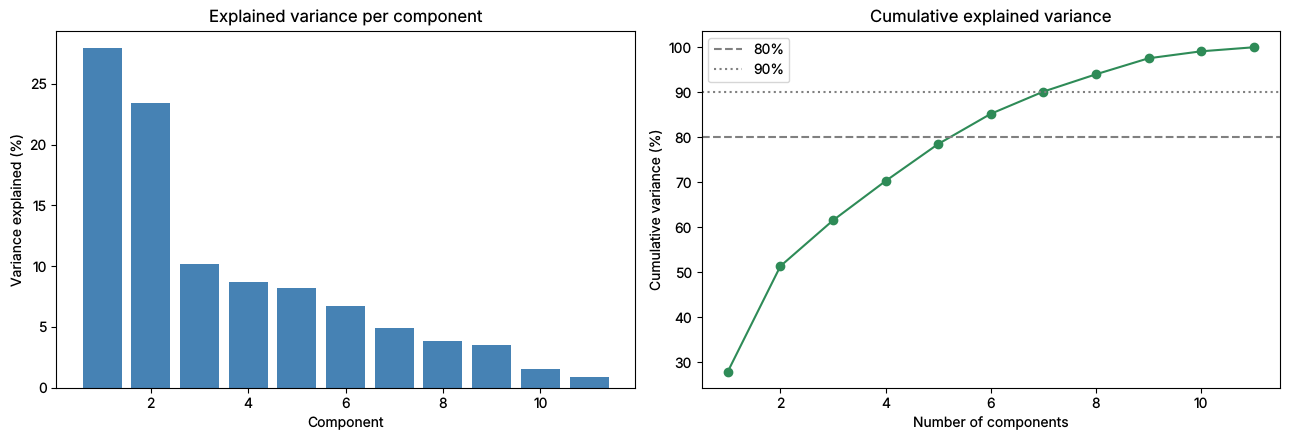

,explained_%,cumulative_%
PC1,28.0,28.0
PC2,23.4,51.4
PC3,10.2,61.5
PC4,8.7,70.3
PC5,8.2,78.5
PC6,6.7,85.2
PC7,4.9,90.1
PC8,3.8,94.0
PC9,3.6,97.6
PC10,1.5,99.1


In [28]:
from sklearn.decomposition import PCA  # PCA squeezes the 11 features into a few components for viewing

pca = PCA(random_state=0).fit(scaled)  # keep all 11 components for now
explained = pca.explained_variance_ratio_
cumulative = explained.cumsum()
components_for_80 = int(np.searchsorted(cumulative, 0.80) + 1)  # first position where the running total passes 80%
components_for_90 = int(np.searchsorted(cumulative, 0.90) + 1)
print(f"{components_for_80=}, {components_for_90=}")

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.5))
left.bar(range(1, len(explained) + 1), explained * 100, color="steelblue")
left.set(xlabel="Component", ylabel="Variance explained (%)", title="Explained variance per component")
right.plot(range(1, len(cumulative) + 1), cumulative * 100, marker="o", color="seagreen")
right.axhline(80, color="gray", linestyle="--", label="80%")
right.axhline(90, color="gray", linestyle=":", label="90%")
right.set(xlabel="Number of components", ylabel="Cumulative variance (%)", title="Cumulative explained variance")
right.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "pca_variance.png", dpi=110)
plt.show()
pd.DataFrame({"explained_%": (explained * 100).round(1), "cumulative_%": (cumulative * 100).round(1)}, index=[f"PC{i}" for i in range(1, 12)])

**What this cell does:** Shows which original features drive the first three components (their loadings).  
**What to look for:** The largest positive and negative numbers in each column.  
**What the output means:** A loading says how much a feature contributes to a component. If PC1 is led by purchase features, then moving along PC1 means 'buys more or less'. This helps us read the 2D plot.

In [29]:
loadings = pd.DataFrame(pca.components_[:3].T, index=kept_features, columns=["PC1", "PC2", "PC3"]).round(2)
loadings.sort_values("PC1", key=abs, ascending=False)

,PC1,PC2,PC3
BALANCE,0.54,0.04,-0.14
CREDIT_LIMIT,0.46,0.03,-0.15
INSTALLMENTS_PURCHASES,0.36,-0.29,0.06
PAYMENTS,0.35,0.20,-0.39
PURCHASES_FREQUENCY,0.28,0.29,0.31
PRC_FULL_PAYMENT,-0.26,0.26,0.25
CASH_ADVANCE,0.22,0.22,0.55
ONEOFF_PURCHASES,-0.11,0.49,-0.29
MINIMUM_PAYMENTS,-0.10,0.54,-0.29
TENURE,0.10,0.17,0.36


**What this cell does:** Projects every customer onto the first two components and plots them, once as points and once as a density map.  
**What to look for:** Is there one blob, several blobs, or a smooth cloud? Are there dense spots and thin edges?  
**What the output means:** This plot is for seeing structure, not for final clustering. Two components keep only part of the information, so groups that overlap here may still be separate in the full 11 dimensions, and groups that look separate here might not be.

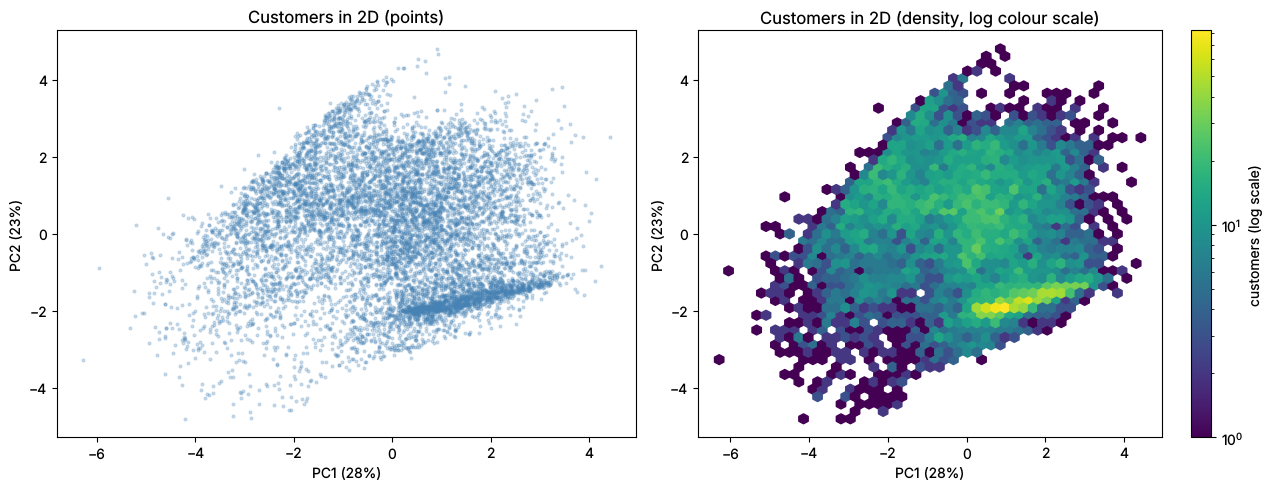

In [30]:
coordinates = pca.transform(scaled)[:, :2]  # first two components for each customer

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 5))
left.scatter(coordinates[:, 0], coordinates[:, 1], s=4, alpha=0.25, color="steelblue")
left.set(xlabel=f"PC1 ({explained[0]:.0%})", ylabel=f"PC2 ({explained[1]:.0%})", title="Customers in 2D (points)")
density = right.hexbin(coordinates[:, 0], coordinates[:, 1], gridsize=45, cmap="viridis", mincnt=1, bins="log")
right.set(xlabel=f"PC1 ({explained[0]:.0%})", ylabel=f"PC2 ({explained[1]:.0%})", title="Customers in 2D (density, log colour scale)")
fig.colorbar(density, ax=right, label="customers (log scale)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "pca_2d.png", dpi=110)
plt.show()

### What PCA tells us

- **The data is not simple.** The first two components hold only 51.4% of the variation. It takes 6 components to pass 80% (85.2%) and 7 to pass 90%. This is why we must not cluster on the 2D picture: it throws away about half of the information. KMeans uses all 11 scaled features.
- **What the first two axes mean** (from the loadings): PC1 (28%) rises with `BALANCE` (0.54), `CREDIT_LIMIT` (0.46), `INSTALLMENTS_PURCHASES` and `PAYMENTS`, so it reads as **account size and activity**. PC2 (23%) is led by `MINIMUM_PAYMENTS` (0.54) and `ONEOFF_PURCHASES` (0.49), so it mostly separates **big one-off buyers from those who do not buy**.
- **There are no clean islands.** The cloud is one continuous mass, so clusters will touch each other. Expect modest scores from the metrics in Step 7 (roughly 0.2 to 0.3 for silhouette, not 0.7) and treat the segments as regions of a continuum.
- **One structure does stand out.** The dense streak at the lower right is 1,297 customers (14%). All of them use cash advances, 94% make no one-off purchases, and the median customer in it has zero purchases of any kind. That is a **cash-advance-only** group, and it is the first segment we can already name.

---
# Part 3: Clustering and cluster profiling
*Steps 7 and 8: KMeans metrics, stability, other methods, robustness checks, profiles and names. Same content as `notebooks/03_clustering.ipynb`.*

**Clustering** means grouping customers so that people in the same group are alike and people in different groups are not. There are no right answers to check against (no labels), so we judge the groups with *internal* measures that only use the data itself, plus a stability test.

We use **KMeans**: pick k centre points, assign each customer to the nearest centre, move each centre to the average of its customers, and repeat until nothing changes. We must choose k ourselves, which is what Step 7 is about.

## Step 7: Clustering and metrics

**What this cell does:** Loads the scaled table made in notebook 02.  
**What to look for:** 8,950 rows and 11 columns, no missing values.  
**What the output means:** This is the data every clustering method below uses. Because it was saved to disk, this notebook runs on its own.

In [31]:
# Imported here so this step only loads the libraries when it runs
from pathlib import Path
import numpy as np  # numpy does fast maths on arrays of numbers
import pandas as pd  # pandas holds and summarises the customer table


def find_project_root(start: Path = Path.cwd()) -> Path:
    """Walk up from the current folder until we see pyproject.toml (nbconvert runs inside notebooks/)."""
    return next(folder for folder in [start, *start.parents] if (folder / "pyproject.toml").exists())


ROOT = find_project_root()
PROCESSED_DIR = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

scaled = pd.read_csv(PROCESSED_DIR / "credit_card_scaled.csv", index_col=0)  # CUST_ID is the row label
print(f"{scaled.shape=}, {scaled.isna().sum().sum()=}")
RANDOM_STATE = 42  # fixed so the results can be repeated
K_VALUES = range(2, 11)

scaled.shape=(8950, 11), scaled.isna().sum().sum()=np.int64(0)


### The four measures

| Measure | What it asks | Better is |
|---|---|---|
| **Inertia** | How far, in total, are customers from their own cluster centre? (Always falls as k grows, so we look for the *elbow* where the gains slow down.) | lower, but only until the elbow |
| **Silhouette** (-1 to 1) | For each customer: am I closer to my own cluster than to the next nearest one? | higher |
| **Davies-Bouldin** | How much do clusters overlap relative to how spread out they are? | lower |
| **Calinski-Harabasz** | Ratio of the spread *between* clusters to the spread *inside* them. | higher |

**What this cell does:** Fits KMeans for every k from 2 to 10 and computes all four measures for each.  
**What to look for:** How each column changes with k. Note where silhouette peaks, where Davies-Bouldin is lowest and where Calinski-Harabasz peaks.  
**What the output means:** The measures often disagree. When they do, we weigh them together with how useful the segments are for the business, rather than trusting one number.

In [32]:
from sklearn.cluster import KMeans  # KMeans groups customers around k centre points
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score  # the three internal quality measures for clusters

kmeans_rows = []
kmeans_labels = {}  # keep the labels for later use
for k in K_VALUES:
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(scaled)  # n_init=10: try 10 starts, keep the best
    kmeans_labels[k] = model.labels_
    kmeans_rows.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(scaled, model.labels_),
        "davies_bouldin": davies_bouldin_score(scaled, model.labels_),
        "calinski_harabasz": calinski_harabasz_score(scaled, model.labels_),
        "smallest_cluster_%": np.bincount(model.labels_).min() / len(scaled) * 100,  # guards against tiny clusters
    })
kmeans_table = pd.DataFrame(kmeans_rows).set_index("k")
kmeans_table.round(3)

,inertia,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster_%
k,,,,,
2,78791.075,0.216,1.896,2232.602,39.095
3,65967.972,0.210,1.624,2202.714,26.212
4,58687.444,0.212,1.597,2020.400,15.162
5,53212.054,0.223,1.506,1901.157,6.905
6,48519.808,0.217,1.502,1840.798,6.648
7,45633.914,0.187,1.506,1725.088,6.603
8,43230.336,0.192,1.477,1631.711,2.726
9,40980.511,0.200,1.431,1567.319,2.726
10,39073.362,0.198,1.452,1509.490,2.715


**What this cell does:** Finds the elbow automatically with the kneed library and plots all four measures against k.  
**What to look for:** A bend in the inertia curve (the dashed line marks kneed's pick) and the peaks or dips in the other three panels.  
**What the output means:** kneed looks for the point where the curve bends most, meaning extra clusters stop paying off (the 'knee'). It is a helpful hint, not a verdict, because real elbows are often gentle.

knee.knee=np.int64(5)


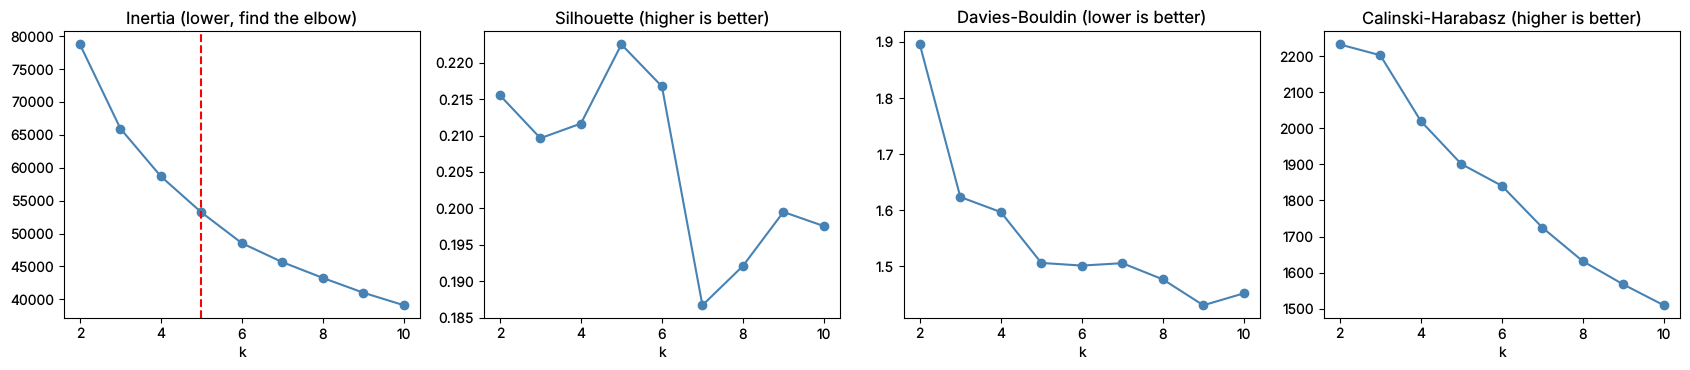

In [33]:
import matplotlib.pyplot as plt  # imported here because plotting starts in this cell
from kneed import KneeLocator   # automatic elbow finder

knee = KneeLocator(list(K_VALUES), kmeans_table["inertia"].tolist(), curve="convex", direction="decreasing")
print(f"{knee.knee=}")

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
plots = [("inertia", "Inertia (lower, find the elbow)"), ("silhouette", "Silhouette (higher is better)"),
         ("davies_bouldin", "Davies-Bouldin (lower is better)"), ("calinski_harabasz", "Calinski-Harabasz (higher is better)")]
for axis, (column, title) in zip(axes, plots):
    axis.plot(kmeans_table.index, kmeans_table[column], marker="o", color="steelblue")
    axis.set(title=title, xlabel="k")
if knee.knee:
    axes[0].axvline(knee.knee, color="red", linestyle="--")  # kneed's elbow pick
fig.tight_layout()
fig.savefig(FIGURES_DIR / "kmeans_metrics.png", dpi=110)
plt.show()

### Stability: would we get the same groups on different customers?

Clusters that appear only for one particular sample are a fluke. To test this, we repeat the following 30 times for each k:

1. Draw a *bootstrap sample* (a random sample of 8,950 customers drawn **with replacement**, so some customers appear twice and others not at all).
2. Fit KMeans on that sample only.
3. Use that model to assign **all** 8,950 customers to a cluster.
4. Compare those labels with our reference labels (from the fit on all data) using the **Adjusted Rand Index (ARI)**.

ARI measures how much two ways of grouping the same customers agree. 1 means identical groupings, 0 means no better than random. Cluster *numbers* do not matter (cluster 2 in one run can be cluster 5 in another), only who is grouped with whom. Each bootstrap fit gets the same 10 random starts as the reference fit, so the comparison is fair (with fewer starts a fit can land on a worse solution and look unstable when it is not). We predict on the full data so both sets of labels cover the same customers. (Comparing the labels of two different bootstrap samples directly is a common mistake, because they contain different people.)

**What this cell does:** Runs the bootstrap stability test for every k and summarises the ARI scores.  
**What to look for:** A high mean ARI (above about 0.8 is solid, below 0.6 is shaky) and a small spread.  
**What the output means:** High stability means the same groups keep appearing when the customers change slightly, so they are not a fluke. A sharp drop at some k suggests the data does not really support that many groups.

In [34]:
from sklearn.metrics import adjusted_rand_score  # Adjusted Rand Index: how much two groupings agree

N_BOOTSTRAPS = 30
random_generator = np.random.default_rng(RANDOM_STATE)  # the modern way to get repeatable randomness
stability_rows = []
for k in K_VALUES:
    reference_labels = kmeans_labels[k]  # labels from the fit on ALL customers
    scores = []
    for _ in range(N_BOOTSTRAPS):
        picked = random_generator.integers(0, len(scaled), size=len(scaled))   # row numbers drawn with replacement
        bootstrap_model = KMeans(n_clusters=k, n_init=10, random_state=int(random_generator.integers(1_000_000))).fit(scaled.iloc[picked])
        predicted_on_all = bootstrap_model.predict(scaled)                     # label every customer with this model
        scores.append(adjusted_rand_score(reference_labels, predicted_on_all)) # agreement with the reference
    stability_rows.append({"k": k, "mean_ARI": np.mean(scores), "std_ARI": np.std(scores), "min_ARI": np.min(scores)})
stability_table = pd.DataFrame(stability_rows).set_index("k")
stability_table.round(3)

,mean_ARI,std_ARI,min_ARI
k,,,
2,0.965,0.032,0.894
3,0.968,0.013,0.944
4,0.924,0.051,0.835
5,0.934,0.031,0.882
6,0.976,0.007,0.961
7,0.917,0.083,0.696
8,0.789,0.133,0.623
9,0.701,0.119,0.540
10,0.766,0.150,0.527


### A second method for comparison

- **Gaussian Mixture Model (GMM):** assumes the data is a mix of k bell-shaped clouds and gives each customer a probability for each cloud. It allows clusters of different sizes and shapes, while KMeans prefers round clusters of similar size.
- **Agglomerative clustering (Ward):** starts with every customer alone and repeatedly merges the two closest groups. Needs no random start.

We compare them with the same internal measures only. We have no true labels, so we do not use accuracy. GMM also reports **BIC** (Bayesian information criterion), a score that rewards a good fit but penalises extra parameters (lower is better).

**What this cell does:** Fits GMM and Agglomerative clustering for k from 2 to 10 and builds one comparison table with the same measures.  
**What to look for:** Whether either method beats KMeans at the same k on silhouette, Davies-Bouldin and Calinski-Harabasz.  
**What the output means:** If a different method gives a similar score, the structure is a property of the data, not of KMeans. If it is clearly better, we should think about switching.

In [35]:
from sklearn.cluster import AgglomerativeClustering  # second method to compare: merges the closest groups step by step
from sklearn.mixture import GaussianMixture  # third method to compare: a mix of bell-shaped clouds (GMM)

comparison_rows = []
gmm_bic = {}
gmm_labels = {}
agglomerative_labels = {}
for k in K_VALUES:
    gmm = GaussianMixture(n_components=k, covariance_type="full", n_init=3, random_state=RANDOM_STATE).fit(scaled)
    gmm_labels[k] = gmm.predict(scaled)       # hard assignment: most likely cloud for each customer
    gmm_bic[k] = gmm.bic(scaled)
    agglomerative_labels[k] = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(scaled)
    for method, label_set in [("KMeans", kmeans_labels), ("GMM", gmm_labels), ("Agglomerative", agglomerative_labels)]:
        labels = label_set[k]
        comparison_rows.append({
            "method": method, "k": k,
            "silhouette": silhouette_score(scaled, labels),
            "davies_bouldin": davies_bouldin_score(scaled, labels),
            "calinski_harabasz": calinski_harabasz_score(scaled, labels),
            "smallest_cluster_%": np.bincount(labels).min() / len(labels) * 100,
        })
comparison_table = pd.DataFrame(comparison_rows)
# One-liner: pivot makes one row per k and one column per method for a chosen measure
display(comparison_table.pivot(index="k", columns="method", values="silhouette").round(3).rename_axis(columns="silhouette"))
display(comparison_table.pivot(index="k", columns="method", values="davies_bouldin").round(3).rename_axis(columns="davies_bouldin"))
display(comparison_table.pivot(index="k", columns="method", values="calinski_harabasz").round(0).rename_axis(columns="calinski_harabasz"))
print("GMM BIC by k (lower is better):")
print(pd.Series(gmm_bic).round(0).to_string())

silhouette,Agglomerative,GMM,KMeans
k,,,
2,0.151,0.144,0.216
3,0.160,0.142,0.210
4,0.164,0.147,0.212
5,0.188,0.148,0.223
6,0.197,0.140,0.217
7,0.175,0.116,0.187
8,0.149,0.087,0.192
9,0.142,0.119,0.200
10,0.150,0.084,0.198


davies_bouldin,Agglomerative,GMM,KMeans
k,,,
2,2.346,2.674,1.896
3,1.999,2.215,1.624
4,1.789,2.672,1.597
5,1.626,3.475,1.506
6,1.545,2.849,1.502
7,1.559,2.718,1.506
8,1.599,2.575,1.477
9,1.591,2.220,1.431
10,1.612,2.827,1.452


calinski_harabasz,Agglomerative,GMM,KMeans
k,,,
2,1428.0,1163.0,2233.0
3,1538.0,1355.0,2203.0
4,1532.0,1166.0,2020.0
5,1536.0,970.0,1901.0
6,1413.0,945.0,1841.0
7,1343.0,869.0,1725.0
8,1294.0,687.0,1632.0
9,1245.0,815.0,1567.0
10,1198.0,694.0,1509.0


GMM BIC by k (lower is better):
2     82133.0
3     31504.0
4      6838.0
5     -1757.0
6    -21529.0
7    -27469.0
8    -68325.0
9    -70849.0
10   -99106.0


### What the metrics tell us

- **KMeans measures are flat and disagree.** Silhouette stays between 0.187 and 0.223 for every k (best at k=5 with 0.223, then k=6 with 0.217). That is a low score: it says the groups touch and overlap, which matches the single continuous cloud we saw in PCA. Davies-Bouldin improves slowly from 1.90 (k=2) to 1.43 (k=9), with k=5, 6 and 7 all near 1.50. Calinski-Harabasz falls steadily from 2,233 (k=2) to 1,509 (k=10), so it always prefers fewer clusters and does not help us choose. kneed puts the elbow at k=5. None of these points to one clear answer.
- **Small clusters appear early.** From k=8 the smallest cluster holds only 2.7% of customers (about 240 people), too small to run a campaign on. At k=5 to 7 the smallest is 6.6% to 6.9%.
- **Stability does separate the options.** With a fair bootstrap (30 resamples, same 10 random starts as the reference fit), k=6 is the most stable: mean ARI 0.976, standard deviation 0.007 and a worst case of 0.961. k=2 and k=3 are also high (0.965 and 0.968). k=5 (0.934) and k=4 (0.924) are good but a little looser, k=7 is 0.917, and from k=8 stability falls to 0.70 to 0.79. So groups beyond 7 are not reliably reproduced.
- **A note on the test itself.** Our first run gave each bootstrap fit only 3 random starts and showed k=5 as shaky (0.77). That was partly the test's fault: with fewer starts the bootstrap fits landed on worse solutions than the reference. Matching the starts removed the problem, so the matched test is the fair one.
- **The other two methods do not beat KMeans.** GMM is worse on all three measures at every k, and Agglomerative has lower silhouette and Calinski-Harabasz, with Davies-Bouldin similar at k=6 (1.545 versus 1.502). Do not read this as "KMeans is the best method". These three measures reward compact, round clusters, which is exactly what KMeans builds, so they favour it by design. What we can say is that Agglomerative at k=6 scores close to KMeans, so the k=6 structure is not only an artefact of KMeans.
- **GMM's BIC cannot be used here.** It keeps falling, down to -99,106 at k=10, and never turns back up. That is a sign of a broken fit, not a good one: with full covariances the model can fit tight clouds around the big piles of zeros and its likelihood grows without limit. It is not evidence for k=10, and we ignore it.

**What this cell does:** Records the k we chose after weighing the metrics, the stability test and the segment descriptions (reasoning in the notes below), plus the runner-up.  
**What to look for:** The two numbers.  
**What the output means:** Everything after this cell uses these two values. Keeping them in one place makes the choice easy to change and to audit.

In [36]:
CHOSEN_K = 6  # our choice (see the reasoning below)
RUNNER_UP_K = 4  # the simpler alternative we check against

### Robustness checks: do our earlier choices change the answer?

In notebooks 01 and 02 we made three choices that we said we would test. For each one we rebuild the data, refit KMeans with the same settings, and measure the **Adjusted Rand Index** against our main grouping. Here ARI is an *agreement between two groupings of the same customers*, not an accuracy (we have no true labels). 1 means the same groups, and values near 0 mean the groups are unrelated.

1. **Drop `MINIMUM_PAYMENTS`**, which is correlated 0.90 with `BALANCE`.
2. **Fill missing `MINIMUM_PAYMENTS` with 0** for customers who made no payments (instead of the median).
3. **Yeo-Johnson** (the runner-up transform) instead of log1p.

**What this cell does:** Rebuilds the data three alternative ways, refits KMeans for the chosen k and the runner-up k, and compares each result with the main grouping.  
**What to look for:** ARI values near 1 (the answer barely changes) versus values below about 0.7, and the '% moved' columns, which say directly what share of customers end up in a different group.  
**What the output means:** If the groups survive these changes, they are a property of the customers and not of one preprocessing decision. If a choice changes them a lot, we must say so in the limitations.

In [37]:
import joblib  # imported here to load the saved preprocessing pipeline from notebook 02
from scipy.optimize import linear_sum_assignment  # imported here to match old and new cluster numbers fairly
from sklearn.base import clone  # imported here to refit the same recipe on changed data
from sklearn.metrics import adjusted_rand_score  # imported here to measure agreement between two groupings
from sklearn.preprocessing import PowerTransformer, StandardScaler  # imported here for the Yeo-Johnson variants

raw = pd.read_csv(ROOT / "data" / "raw" / "credit_card.csv").set_index("CUST_ID")
saved_pipeline = joblib.load(PROCESSED_DIR / "preprocessing_pipeline.joblib")
imputed_original = pd.read_csv(PROCESSED_DIR / "credit_card_imputed_original_units.csv", index_col=0)

# Variant 2: customers with no payments and a blank minimum payment get 0 instead of the median
raw_zero_fill = raw.copy()
no_payment_blank = raw_zero_fill["MINIMUM_PAYMENTS"].isna() & (raw_zero_fill["PAYMENTS"] == 0)
raw_zero_fill.loc[no_payment_blank, "MINIMUM_PAYMENTS"] = 0
print(f"{no_payment_blank.sum()=} customers filled with 0")

# The seven skewed money columns that Option B logs (list from notebook 02); the other four are bounded
log_features = ["BALANCE", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS", "MINIMUM_PAYMENTS"]
plain_features = [name for name in scaled.columns if name not in log_features]

# Like-for-like Yeo-Johnson: replaces log1p on the SAME seven columns, and leaves the four bounded columns with plain scaling
yeo_johnson_money_only = pd.concat([
    pd.DataFrame(PowerTransformer(method="yeo-johnson").fit_transform(imputed_original[log_features]), columns=log_features, index=scaled.index),
    pd.DataFrame(StandardScaler().fit_transform(imputed_original[plain_features]), columns=plain_features, index=scaled.index),
], axis=1)[scaled.columns]

variants = {
    "Drop MINIMUM_PAYMENTS": scaled.drop(columns="MINIMUM_PAYMENTS"),
    "Zero-fill MINIMUM_PAYMENTS": clone(saved_pipeline).fit_transform(raw_zero_fill),  # same recipe, refit on changed data
    "Yeo-Johnson instead of log1p (same 7 columns)": yeo_johnson_money_only,
    "Yeo-Johnson on all 11 columns": pd.DataFrame(
        PowerTransformer(method="yeo-johnson").fit_transform(imputed_original[scaled.columns]),
        columns=scaled.columns, index=scaled.index),
}


def share_reassigned(main_labels, new_labels) -> float:
    """Share of customers whose group changes after matching the new cluster numbers to the old ones as well as possible."""
    overlap = pd.crosstab(main_labels, new_labels).values            # how many customers each old/new pair share
    old_index, new_index = linear_sum_assignment(-overlap)           # best one-to-one matching (minus sign: maximise overlap)
    return 1 - overlap[old_index, new_index].sum() / overlap.sum()   # everyone not in a matched pair has moved


sensitivity_rows = []
for variant_name, variant_data in variants.items():
    row = {"variant": variant_name}
    for k in (CHOSEN_K, RUNNER_UP_K):
        variant_labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(variant_data)
        row[f"ARI at k={k}"] = adjusted_rand_score(kmeans_labels[k], variant_labels)  # vs the main grouping at the same k
        row[f"% moved at k={k}"] = share_reassigned(kmeans_labels[k], variant_labels) * 100  # share of customers who change group
    sensitivity_rows.append(row)
pd.DataFrame(sensitivity_rows).set_index("variant").round(3)

no_payment_blank.sum()=np.int64(240) customers filled with 0


,ARI at k=6,% moved at k=6,ARI at k=4,% moved at k=4
variant,,,,
Drop MINIMUM_PAYMENTS,0.847,6.514,0.875,5.207
Zero-fill MINIMUM_PAYMENTS,0.902,4.380,0.901,4.279
Yeo-Johnson instead of log1p (same 7 columns),0.917,3.497,0.797,8.715
Yeo-Johnson on all 11 columns,0.669,17.374,0.746,11.419


### What the robustness checks tell us

| Change | ARI at k=6 | % of customers who change group | ARI at k=4 | % moved at k=4 |
|---|---|---|---|---|
| Drop `MINIMUM_PAYMENTS` | 0.85 | 6.5% | 0.88 | 5.2% |
| Fill blank minimum payments with 0 (for customers with no payments) | 0.90 | 4.4% | 0.90 | 4.3% |
| Yeo-Johnson instead of log1p, on the **same 7 money columns** | **0.92** | **3.5%** | 0.80 | 8.7% |
| Yeo-Johnson on **all 11 columns** (also reshapes the 3 bounded ones) | 0.67 | 17.4% | 0.75 | 11.4% |

*"% moved" is the share of customers placed in a different group, after matching the new cluster numbers to the old ones as well as possible. ARI is a score of agreement; "% moved" is the easier number to read.*

- **Dropping the feature or filling zeros changes little:** 4% to 7% of customers move. The median-imputation decision from notebook 01 and the 0.90 correlation pair are not driving the result.
- **Swapping log1p for Yeo-Johnson on the same seven columns barely matters** at k=6 (3.5% move), and k=6 is clearly sturdier than k=4 on this test (0.92 against 0.80).
- **What matters is the treatment of the three bounded columns.** When Yeo-Johnson also reshapes `TENURE`, `BALANCE_FREQUENCY` and `PRC_FULL_PAYMENT`, 17.4% of customers move at k=6. Those three columns are the signature features of three of our clusters (newer, dormant, pay in full), so reshaping them changes who sits close to whom. Our first version of this check mixed the two effects together, which made the transform look more important than it is. We chose to leave the bounded columns as they are (they are shares or a near-constant, so a skew correction is the wrong tool), but this is a modelling choice, and a different one gives noticeably different boundaries. We report it as a limitation.

### Decision: k = 6 (runner-up: k = 4)

**The trade-off in plain words.** Fewer groups are easier to explain and to act on. More groups catch finer differences, but each extra group is a worse bet: smaller, less stable and harder to tell apart. We look for the point just before the extra groups stop being reliable.

**Why 6:**
1. **Most stable:** ARI 0.976 with a worst case of 0.961. These six groups come back almost unchanged when the customers are resampled.
2. **Davies-Bouldin is as good as at k=5 or 7** (about 1.50) and better than k=4 (1.60). Silhouette (0.217) is essentially equal to every other k.
3. **Every group is large enough to act on** (the smallest is 6.6% of customers, 595 people).
4. **Business value:** moving from 4 to 6 separates a group of large-limit, high-balance, high-spending customers (about 18% of the base) from the other active customers. That is exactly the kind of group a credit limit review would target, and at k=4 it is blended in.

**Why not k=4 (runner-up):** it is simpler, and it holds up a little better only if all 11 columns are reshaped (0.75 against 0.67). On the like-for-like transform check k=6 is the sturdier one. k=4 is a perfectly reasonable choice for a short executive summary. It just blends together groups whose needs differ.

**An honest caveat:** silhouette near 0.2 means these are *practical divisions of a continuous range of customers*, not natural islands. The segments are useful, and stable under resampling, but a customer near a boundary could easily have been placed in the next group.

**What this cell does:** Fits the final KMeans model with the chosen k and saves the cluster labels and the model to data/processed/.  
**What to look for:** The size of each cluster, and that the two saved files exist.  
**What the output means:** Notebook 04 loads these files to explain the clusters. The model's centroids (cluster centres) follow the column order of the scaled table, which puts the log-transformed columns first.

In [38]:
final_model = KMeans(n_clusters=CHOSEN_K, n_init=10, random_state=RANDOM_STATE).fit(scaled)
cluster_labels = pd.Series(final_model.labels_, index=scaled.index, name="cluster")
assert (cluster_labels.values == kmeans_labels[CHOSEN_K]).all()  # same settings as the table above, so identical labels

cluster_labels.to_csv(PROCESSED_DIR / "cluster_labels.csv")                 # one row per customer
joblib.dump(final_model, PROCESSED_DIR / f"kmeans_k{CHOSEN_K}.joblib")      # the fitted model (centroids inside)
print(sorted(path.name for path in PROCESSED_DIR.glob("*") if path.name != ".gitkeep"))
cluster_labels.value_counts().sort_index().to_frame("customers").assign(percent=lambda t: (t["customers"] / len(scaled) * 100).round(1))

['cluster_labels.csv', 'credit_card_imputed_original_units.csv', 'credit_card_scaled.csv', 'kmeans_k6.joblib', 'preprocessing_pipeline.joblib']


,customers,percent
cluster,,
0,595,6.6
1,2051,22.9
2,1248,13.9
3,1635,18.3
4,2406,26.9
5,1015,11.3


---
## Step 8: Cluster profiling

Now we describe who is in each cluster, in plain money terms. We use the **original dollar values** (after filling blanks) and all 17 original features, including the six we dropped for clustering, because they help explain each group even though they were not used to build it.

**What this cell does:** Loads the original-unit data and the cluster labels, and joins them into one table.  
**What to look for:** 17 feature columns plus a `cluster` column, and 8,950 rows.  
**What the output means:** Each customer now has their real values and their cluster, which is what we need to describe the groups.

In [39]:
imputed_original = pd.read_csv(PROCESSED_DIR / "credit_card_imputed_original_units.csv", index_col=0)  # all 17, blanks filled
labels = pd.read_csv(PROCESSED_DIR / "cluster_labels.csv", index_col=0)["cluster"]
profile_data = imputed_original.join(labels)  # align on CUST_ID
print(f"{profile_data.shape=}, {profile_data['cluster'].nunique()=}")

profile_data.shape=(8950, 18), profile_data['cluster'].nunique()=6


**What this cell does:** Computes the size of each cluster as a percentage of customers, and the mean and median of every feature per cluster.  
**What to look for:** Compare the mean with the median within a cluster: a mean far above the median means a few very large customers inside that group.  
**What the output means:** Medians describe the typical member. Means include the big customers, so they show where the money is. We use both on purpose.

In [40]:
cluster_sizes = profile_data["cluster"].value_counts().sort_index()
size_table = pd.DataFrame({"customers": cluster_sizes, "percent": (cluster_sizes / len(profile_data) * 100).round(1)})
display(size_table)

cluster_means = profile_data.groupby("cluster").mean().round(2)      # average per feature, per cluster
cluster_medians = profile_data.groupby("cluster").median().round(2)  # typical customer per feature, per cluster
print("MEDIANS (the typical customer in each cluster)")
display(cluster_medians.T)   # .T puts features on the rows so the table fits on screen
print("MEANS (pulled up by the biggest customers)")
display(cluster_means.T)

,customers,percent
cluster,,
0,595,6.6
1,2051,22.9
2,1248,13.9
3,1635,18.3
4,2406,26.9
5,1015,11.3


MEDIANS (the typical customer in each cluster)


cluster,0,1,2,3,4,5
BALANCE,563.46,603.69,94.18,2716.49,1765.21,14.04
BALANCE_FREQUENCY,0.88,1.00,1.00,1.00,1.00,0.36
PURCHASES,175.80,496.56,1043.32,1704.95,0.00,136.72
ONEOFF_PURCHASES,0.00,103.00,169.14,856.28,0.00,0.00
INSTALLMENTS_PURCHASES,0.00,206.32,517.64,608.76,0.00,19.50
CASH_ADVANCE,531.96,0.00,0.00,433.91,1274.88,0.00
PURCHASES_FREQUENCY,0.33,0.67,1.00,0.92,0.00,0.17
ONEOFF_PURCHASES_FREQUENCY,0.00,0.08,0.09,0.42,0.00,0.00
PURCHASES_INSTALLMENTS_FREQUENCY,0.00,0.42,0.75,0.75,0.00,0.08
CASH_ADVANCE_FREQUENCY,0.14,0.00,0.00,0.08,0.25,0.00


MEANS (pulled up by the biggest customers)


cluster,0,1,2,3,4,5
BALANCE,923.70,745.94,183.79,3447.92,2497.88,45.22
BALANCE_FREQUENCY,0.82,0.97,0.90,0.99,0.95,0.35
PURCHASES,404.94,706.17,1911.48,2662.82,107.50,287.19
ONEOFF_PURCHASES,263.79,371.70,1058.17,1624.21,99.90,164.02
INSTALLMENTS_PURCHASES,141.66,334.87,853.86,1038.66,7.65,123.86
CASH_ADVANCE,1200.34,84.71,59.23,1560.52,2107.19,175.06
PURCHASES_FREQUENCY,0.42,0.63,0.84,0.83,0.06,0.29
ONEOFF_PURCHASES_FREQUENCY,0.13,0.20,0.35,0.44,0.04,0.07
PURCHASES_INSTALLMENTS_FREQUENCY,0.28,0.47,0.66,0.65,0.01,0.21
CASH_ADVANCE_FREQUENCY,0.21,0.03,0.01,0.19,0.28,0.02


**What this cell does:** Draws a heatmap of cluster means. Each feature (row) is rescaled from 0 to 1 across the six clusters.  
**What to look for:** Dark cells mean a cluster is the highest on that feature, pale cells the lowest. Read across a row to see which clusters stand out.  
**What the output means:** Rescaling per feature lets us compare features that have very different units (dollars versus shares). It shows only the *ranking between clusters*, not how large the gap is, so read it together with the tables above.

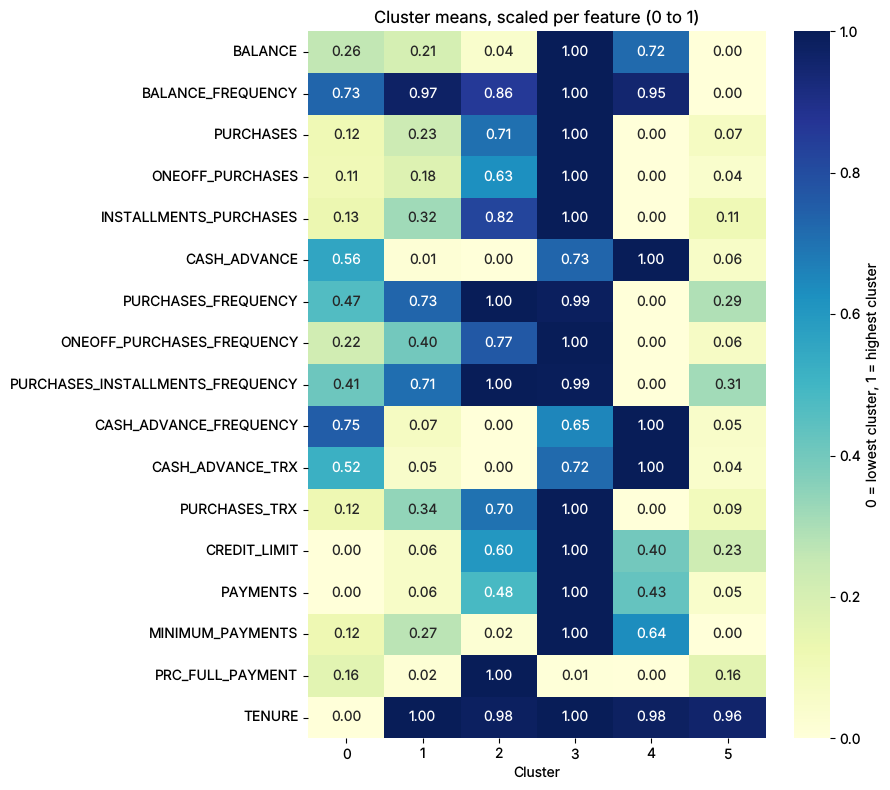

In [41]:
import matplotlib.pyplot as plt  # imported here because plotting starts in this cell
import seaborn as sns  # seaborn draws statistical plots on top of matplotlib

feature_means = profile_data.groupby("cluster").mean()
# One-liner: (value - column min) / (column max - column min) rescales each feature to 0..1 across clusters
means_scaled = (feature_means - feature_means.min()) / (feature_means.max() - feature_means.min())

plt.figure(figsize=(9, 8))
sns.heatmap(means_scaled.T, annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={"label": "0 = lowest cluster, 1 = highest cluster"})
plt.title("Cluster means, scaled per feature (0 to 1)")
plt.xlabel("Cluster")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cluster_heatmap.png", dpi=110)
plt.show()

### Reading the profile

How each group differs, from the medians (typical member) and means (where the money is):

| Cluster | Share | What stands out | Name |
|---|---|---|---|
| 3 | 18.3% | Highest balance (median 2,716), highest purchases (median 1,705, mean 2,663), highest credit limit (7,000) and highest payments, **and** also cash advances (mean 1,561). Almost never pays in full (mean 3%). | **Big spenders, high limit, carry a balance** |
| 2 | 13.9% | Buys in almost every period (purchase frequency 1.0) with real volume (median 1,043), yet has the lowest balance of the active groups (median 94) because it scores high on the full-payment measure `PRC_FULL_PAYMENT` (median 0.80). Limit 4,500. | **Frequent buyers, pay in full** |
| 1 | 22.9% | Regular but moderate purchases (median 497, frequency 0.67), no cash advances, a small limit (2,000), and a balance that is carried (never pays in full). | **Steady everyday spenders** |
| 4 | 26.9% | Almost no purchases (mean frequency 0.06) but the biggest cash advances (median 1,275, mean 2,107), a balance of 1,765 that is carried, and limit 3,000. | **Cash advance borrowers** |
| 0 | 6.6% | Short tenure (median **7 months**, versus 12 for everyone else), the smallest limit (1,500), and a mix of small purchases and cash advances. | **Newer customers, small limit, mixed use** |
| 5 | 11.3% | Balance of about 14 and a balance that is rarely updated (balance frequency 0.36), small purchases (frequency 0.17), no cash advances. | **Dormant, barely used card** |

**Why these names, and what to keep in mind.** A name should tell a manager what the group does with the card, in a few words. They come from three things: how much and how often the group buys, whether it borrows (cash advance or carried balance), and whether it pays in full. Cluster 3 mixes two roles (heavy spending and heavy borrowing), which is why its name carries both. Cluster 0 is separated mainly by its short tenure, so we should not read too much into how it spends, since a newer customer has had less time to build up a record. The cluster numbers (0 to 5) are arbitrary labels from KMeans and could change if the model is refit with another seed. The names are what stay meaningful.

*Measured from the data:* only cluster 2 scores high on the full-payment measure `PRC_FULL_PAYMENT` (mean 0.75), while every other group averages between 0.03 and 0.15. So paying in full is a defining trait of one group only. (There is no data dictionary, so we read this column as the share of the bill, or of billing periods, paid in full.)

**What this cell does:** Saves the cluster names and the profile tables, so the next notebook and the README can use them.  
**What to look for:** The printed dictionary of names.  
**What the output means:** Names are saved next to the data so notebook 04 uses exactly the same words. The profile tables go to reports/ for the write-up.

In [42]:
import json  # json saves and reads the cluster names as a small text file

cluster_names = {
    0: "Newer customers, small limit, mixed use",
    1: "Steady everyday spenders",
    2: "Frequent buyers, pay in full",
    3: "Big spenders, high limit, carry a balance",
    4: "Cash advance borrowers",
    5: "Dormant, barely used card",
}
(PROCESSED_DIR / "cluster_names.json").write_text(json.dumps(cluster_names, indent=2))  # names for notebook 04

named_profile = cluster_medians.T.copy()
named_profile.columns = [f"{cluster}: {cluster_names[cluster]}" for cluster in named_profile.columns]
named_profile.to_csv(FIGURES_DIR.parent / "cluster_profile_medians.csv")  # reports/cluster_profile_medians.csv
cluster_means.T.to_csv(FIGURES_DIR.parent / "cluster_profile_means.csv")
size_table.assign(name=size_table.index.map(cluster_names))

,customers,percent,name
cluster,,,
0,595,6.6,"Newer customers, small limit, mixed use"
1,2051,22.9,Steady everyday spenders
2,1248,13.9,"Frequent buyers, pay in full"
3,1635,18.3,"Big spenders, high limit, carry a balance"
4,2406,26.9,Cash advance borrowers
5,1015,11.3,"Dormant, barely used card"


---
# Part 4: Explainability
*Step 9: surrogate model, SHAP, distance contributions, permutation importance. Same content as `notebooks/04_explainability.ipynb`.*

## Step 9: Why did customers end up in these clusters?

**XAI** (explainable AI) means tools that show *why* a model gave its answer. KMeans has no built-in "feature importance", because it never predicted anything from labels. So we use four indirect methods:

1. **Surrogate model.** We train a supervised model (a Random Forest) to *predict the cluster label* from the customer's features. If it predicts well, the clusters can be described by simple rules on the features.
2. **SHAP** (SHapley Additive exPlanations). For each customer and each feature, SHAP gives a number that says how much that feature pushed the surrogate towards a cluster. It is based on fair-share ideas from game theory.
3. **Distance contributions.** KMeans assigns a customer to the nearest cluster centre. We split that distance feature by feature to see which features pull a customer towards their own centre. This one explains KMeans directly.
4. **Permutation importance.** Shuffle one feature at a time and see how much the surrogate's accuracy drops. A big drop means the feature matters. It is a cross-check on SHAP.

**Limitation to keep in mind:** these tools explain the clusters *the model found* and the *surrogate's behaviour*. They do not reveal a hidden truth about customers. We report how faithful the surrogate is (its *fidelity*) so you know how far to trust them.

**What this cell does:** Loads the original-unit data (11 clustering features), the cluster labels, the cluster names, the scaled data and the saved KMeans model.  
**What to look for:** 11 feature columns, 8,950 rows, and six cluster names.  
**What the output means:** We use the features in their original dollar units for the surrogate, so every explanation later reads in real money. Tree models are not affected by log or scaling (they only compare 'bigger than', not distances), so this does not change which splits they find.

In [43]:
# Imported here so this step only loads the libraries when it runs
import json
from pathlib import Path  # Path builds file locations that work on any operating system

import joblib  # joblib loads the saved model and pipeline from disk
import numpy as np  # numpy does fast maths on arrays of numbers
import pandas as pd  # pandas holds and summarises the customer table


def find_project_root(start: Path = Path.cwd()) -> Path:
    """Walk up from the current folder until we see pyproject.toml (nbconvert runs inside notebooks/)."""
    return next(folder for folder in [start, *start.parents] if (folder / "pyproject.toml").exists())


ROOT = find_project_root()
PROCESSED_DIR = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "reports" / "figures"
RANDOM_STATE = 42

scaled = pd.read_csv(PROCESSED_DIR / "credit_card_scaled.csv", index_col=0)
imputed_original = pd.read_csv(PROCESSED_DIR / "credit_card_imputed_original_units.csv", index_col=0)
labels = pd.read_csv(PROCESSED_DIR / "cluster_labels.csv", index_col=0)["cluster"]
cluster_names = {int(key): value for key, value in json.loads((PROCESSED_DIR / "cluster_names.json").read_text()).items()}
kmeans_model = joblib.load(PROCESSED_DIR / "kmeans_k6.joblib")

features = scaled.columns.tolist()          # same 11 columns, same order the model was trained on
original_units = imputed_original[features]  # the same 11 features, in dollars and counts
print(f"{original_units.shape=}, {labels.shape=}")
print(cluster_names)

original_units.shape=(8950, 11), labels.shape=(8950,)
{0: 'Newer customers, small limit, mixed use', 1: 'Steady everyday spenders', 2: 'Frequent buyers, pay in full', 3: 'Big spenders, high limit, carry a balance', 4: 'Cash advance borrowers', 5: 'Dormant, barely used card'}


### 1. Surrogate model

We split customers into a **training set** (75%) to build the surrogate and a **test set** (25%) it has never seen. Accuracy on the test set is the honest measure of how well the clusters can be recreated from the features. `stratify` keeps the same cluster proportions in both parts.

We also run **cross-validation**: the data is split into 5 parts, and the model is trained on 4 and tested on the 5th, five times in turn. If the five scores are similar, the result does not depend on one lucky split.

**What this cell does:** Splits the customers, trains a Random Forest to predict the cluster, and reports test accuracy, 5-fold cross-validated accuracy and a per-cluster report.  
**What to look for:** Accuracy far above the 'always guess the biggest cluster' baseline (26.9%), and which clusters have lower recall (the share of that cluster's customers the model found).  
**What the output means:** High accuracy means the clusters are easy to describe with the features, so explanations based on the surrogate are trustworthy. Low accuracy would be a warning: the explanations would be describing something the surrogate itself cannot reproduce.

In [44]:
from sklearn.ensemble import RandomForestClassifier  # the surrogate model that learns to predict the cluster
from sklearn.metrics import classification_report  # per-cluster precision and recall
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split  # splitting and cross-validation tools

X_train, X_test, y_train, y_test = train_test_split(
    original_units, labels, test_size=0.25, stratify=labels, random_state=RANDOM_STATE)

surrogate = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE)
surrogate.fit(X_train, y_train)

test_accuracy = surrogate.score(X_test, y_test)  # accuracy on customers the model has never seen
baseline = labels.value_counts(normalize=True).max()  # what 'always guess the biggest cluster' would score
cv_scores = cross_val_score(
    RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE),
    original_units, labels, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="accuracy")
print(f"{test_accuracy=:.3f}  {baseline=:.3f}")
print(f"{cv_scores.round(3)=}  mean={cv_scores.mean():.3f}  std={cv_scores.std():.3f}")
print(classification_report(y_test, surrogate.predict(X_test), target_names=[cluster_names[c] for c in sorted(cluster_names)], digits=3))

test_accuracy=0.950  baseline=0.269
cv_scores.round(3)=array([0.954, 0.958, 0.951, 0.945, 0.946])  mean=0.951  std=0.005
                                           precision    recall  f1-score   support

  Newer customers, small limit, mixed use      0.922     0.946     0.934       149
                 Steady everyday spenders      0.933     0.951     0.942       513
             Frequent buyers, pay in full      0.955     0.949     0.952       312
Big spenders, high limit, carry a balance      0.951     0.941     0.946       409
                   Cash advance borrowers      0.975     0.970     0.972       601
                Dormant, barely used card      0.940     0.921     0.930       254

                                 accuracy                          0.950      2238
                                macro avg      0.946     0.946     0.946      2238
                             weighted avg      0.951     0.950     0.950      2238



**What this cell does:** Shows the confusion matrix of the surrogate on the test customers.  
**What to look for:** Strong values on the diagonal, and which pairs of clusters get mixed up (off-diagonal cells).  
**What the output means:** Rows are the true cluster, columns what the surrogate predicted. Confusion between two clusters means they sit next to each other in feature space, which agrees with the touching clouds we saw in PCA.

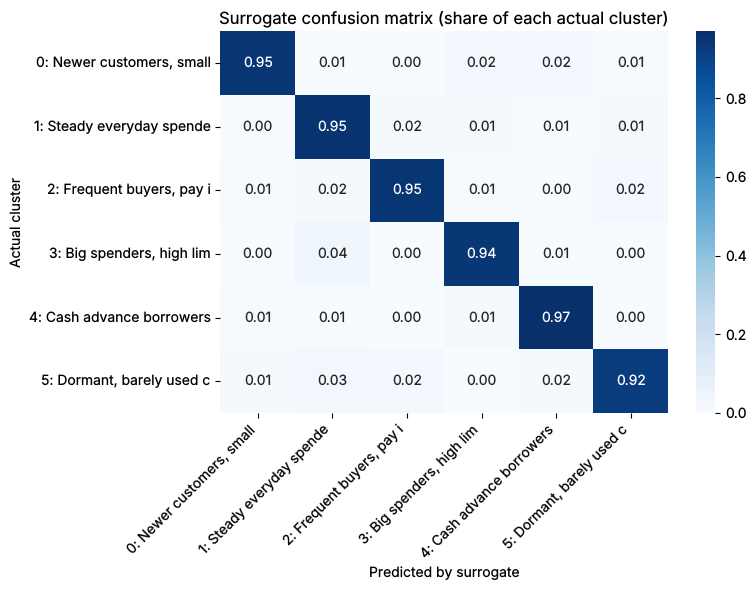

In [45]:
import matplotlib.pyplot as plt  # imported here because plotting starts in this cell
import seaborn as sns  # seaborn draws statistical plots on top of matplotlib
from sklearn.metrics import confusion_matrix  # counts which clusters the surrogate mixes up

matrix = confusion_matrix(y_test, surrogate.predict(X_test), normalize="true")  # each row sums to 1
short_names = [f"{c}: {cluster_names[c][:22]}" for c in sorted(cluster_names)]
plt.figure(figsize=(8, 6))
sns.heatmap(matrix, annot=True, fmt=".2f", cmap="Blues", xticklabels=short_names, yticklabels=short_names)
plt.xlabel("Predicted by surrogate"); plt.ylabel("Actual cluster")
plt.title("Surrogate confusion matrix (share of each actual cluster)")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
plt.savefig(FIGURES_DIR / "surrogate_confusion.png", dpi=110)
plt.show()

### What the surrogate tells us (and its fidelity)

- **Fidelity is high: 95.0% on customers it never saw** (cross-validated: 95.1%, folds between 94.5% and 95.8%), against a 26.9% baseline for always guessing the biggest cluster. In other words, the surrogate reproduces KMeans's cluster for 19 customers out of 20. Recall (how many of a cluster's members it found) ranges from 92.1% (dormant) to 97.0% (cash advance borrowers).
- **Where it goes wrong:** the top confusion is 17 big spenders (of 409) predicted as steady everyday spenders, followed by smaller mixes of the same neighbours. Mistakes happen between clusters that sit next to each other, which fits the touching clouds we saw in PCA.
- **How to read the 95%.** KMeans is itself a fixed rule on these same features (nearest centre), so a flexible model learning that rule is expected to do well. High accuracy tells us the clusters are *describable* with the features. It does **not** prove the clusters are meaningful or that customers truly fall into six types. A low score would have been the warning sign, and we do not have one.

### 2. SHAP

For each customer, SHAP splits the surrogate's prediction into one contribution per feature. For cluster *c*, a **positive** SHAP value means "this feature value pushed the model towards cluster *c*" and a **negative** one means it pushed away. Contributions are in the model's probability units. We explain the **test customers** (never used to train the surrogate).

`shap.TreeExplainer` is the fast, exact method for tree models such as a Random Forest.

**What this cell does:** Computes SHAP values for the test customers and prints the shape of the result.  
**What to look for:** The shape should be (customers, features, clusters) = (about 2,238, 11, 6).  
**What the output means:** Each customer has one SHAP value per feature per cluster. The third axis is the cluster, which we need for the plots below.

In [46]:
import shap  # imported here because SHAP is slow to load and only needed from this step on

explainer = shap.TreeExplainer(surrogate)                    # exact explanations for tree ensembles
shap_values = explainer(X_test, check_additivity=False)      # an Explanation object; skip the slow additivity check
print(f"{shap_values.values.shape=}  (customers, features, clusters)")

shap_values.values.shape=(2238, 11, 6)  (customers, features, clusters)


**What this cell does:** Draws the global SHAP summary: the average size of each feature's contribution, split by cluster.  
**What to look for:** Which features have the longest bars, and which colours (clusters) dominate each bar.  
**What the output means:** A long bar means the feature moves predictions a lot, on average. The colours show for which clusters it matters, so a feature may be vital for one cluster and irrelevant for the others.

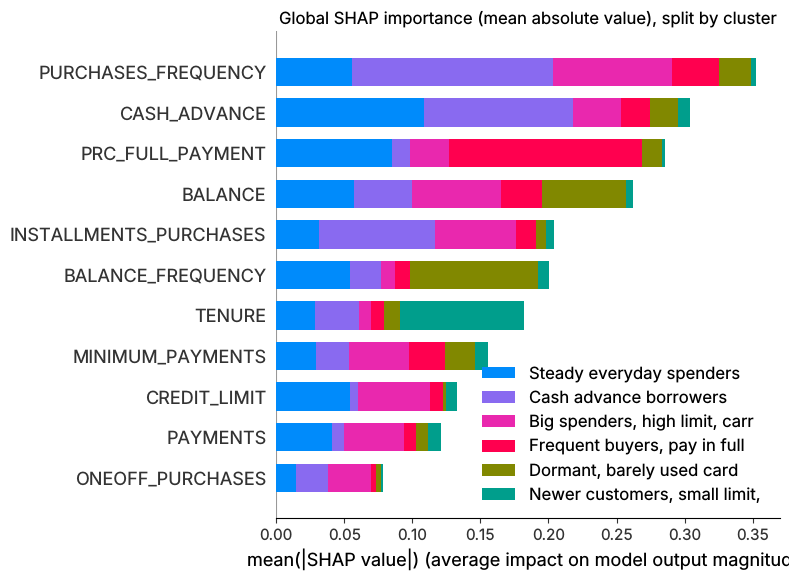

,"Newer customers, small limit, mixed use",Steady everyday spenders,"Frequent buyers, pay in full","Big spenders, high limit, carry a balance",Cash advance borrowers,"Dormant, barely used card",ALL CLUSTERS
PURCHASES_FREQUENCY,0.004,0.055,0.035,0.087,0.148,0.024,0.352
CASH_ADVANCE,0.009,0.109,0.021,0.035,0.109,0.020,0.304
PRC_FULL_PAYMENT,0.003,0.085,0.142,0.029,0.013,0.014,0.286
BALANCE,0.005,0.057,0.030,0.065,0.043,0.062,0.262
INSTALLMENTS_PURCHASES,0.006,0.031,0.014,0.060,0.086,0.007,0.204
BALANCE_FREQUENCY,0.008,0.054,0.011,0.010,0.023,0.094,0.200
TENURE,0.091,0.029,0.010,0.008,0.032,0.012,0.182
MINIMUM_PAYMENTS,0.010,0.029,0.026,0.044,0.024,0.022,0.156
CREDIT_LIMIT,0.008,0.054,0.009,0.053,0.006,0.002,0.133
PAYMENTS,0.010,0.041,0.009,0.044,0.009,0.009,0.121


In [47]:
plt.figure()
shap.summary_plot(
    shap_values.values, X_test, plot_type="bar", show=False,
    class_names=[cluster_names[c][:30] for c in sorted(cluster_names)])  # one coloured segment per cluster
plt.title("Global SHAP importance (mean absolute value), split by cluster")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "shap_global_bar.png", dpi=110, bbox_inches="tight")
plt.show()

# The same numbers as a table: mean |SHAP| per feature (rows) and cluster (columns)
mean_abs_shap = pd.DataFrame(
    np.abs(shap_values.values).mean(axis=0), index=features, columns=[cluster_names[c] for c in sorted(cluster_names)])
mean_abs_shap["ALL CLUSTERS"] = mean_abs_shap.sum(axis=1)
mean_abs_shap.sort_values("ALL CLUSTERS", ascending=False).round(3)

**What this cell does:** Draws a beeswarm SHAP plot for the cluster with the most distinctive profile (the 'big spenders'), so we can see direction as well as size.  
**What to look for:** Each dot is a customer. Red means a high feature value, blue a low one. Dots to the right pushed towards this cluster.  
**What the output means:** This shows direction: for example, red dots on the right for BALANCE means a high balance pushes a customer into this cluster.

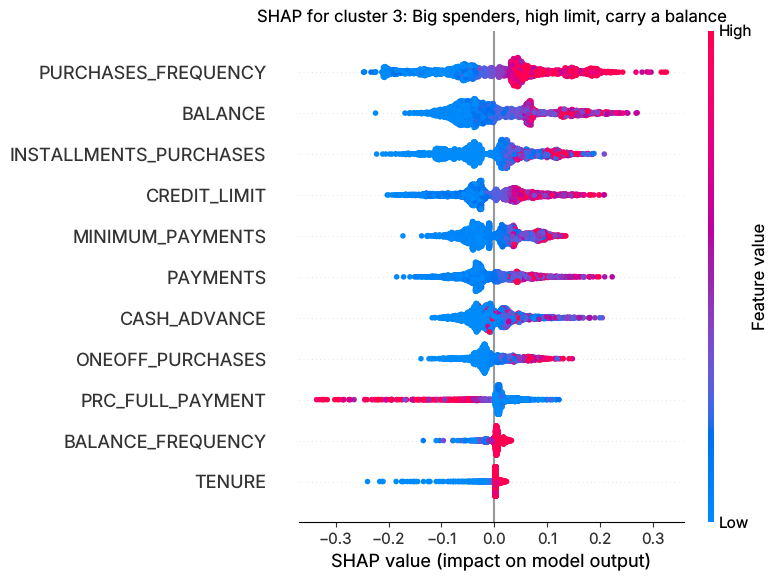

In [48]:
BIG_SPENDERS = 3  # cluster number from notebook 03 (named 'Big spenders, high limit, carry a balance')
plt.figure()
shap.plots.beeswarm(shap_values[:, :, BIG_SPENDERS], show=False, max_display=11)
plt.title(f"SHAP for cluster {BIG_SPENDERS}: {cluster_names[BIG_SPENDERS]}")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "shap_beeswarm_cluster3.png", dpi=110, bbox_inches="tight")
plt.show()

**What this cell does:** Picks one typical customer from each cluster (the test customer closest to that cluster's centre) and draws a SHAP waterfall plot for each.  
**What to look for:** The bars show how each feature pushed the probability of the customer's own cluster up (red) or down (blue), starting from the average and ending at the model's final value f(x).  
**What the output means:** A waterfall explains one customer. Reading it top to bottom tells the story: 'this customer is in this cluster mainly because of these two or three features'. Feature values are shown in real units, as dollars or counts.

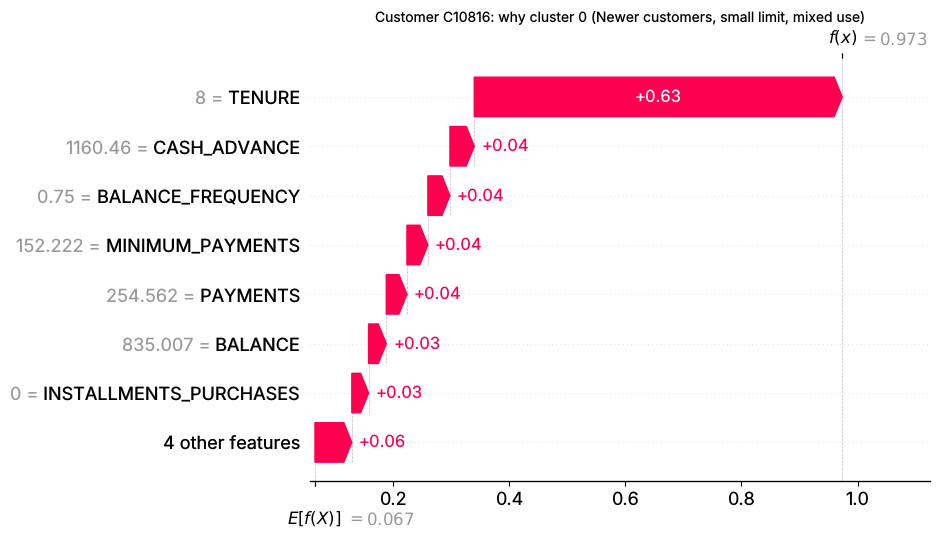

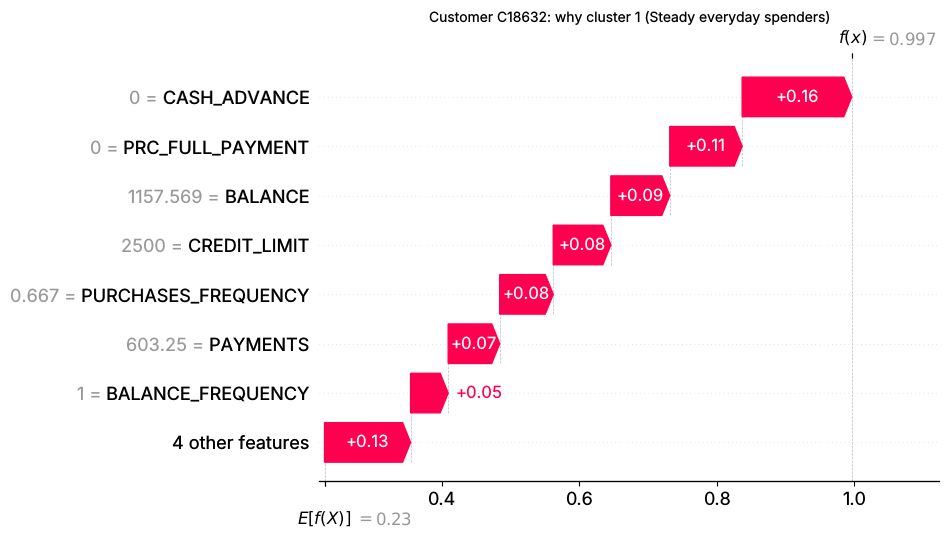

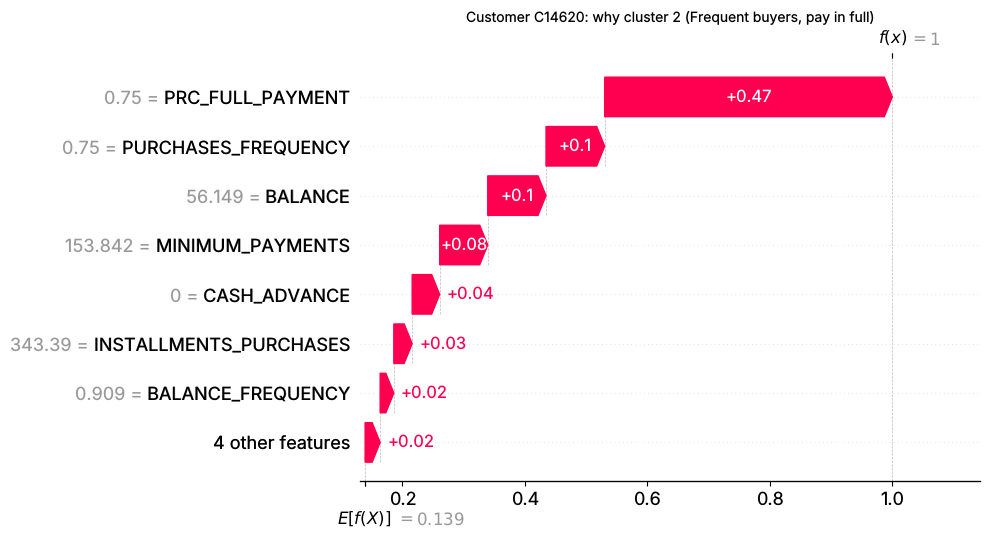

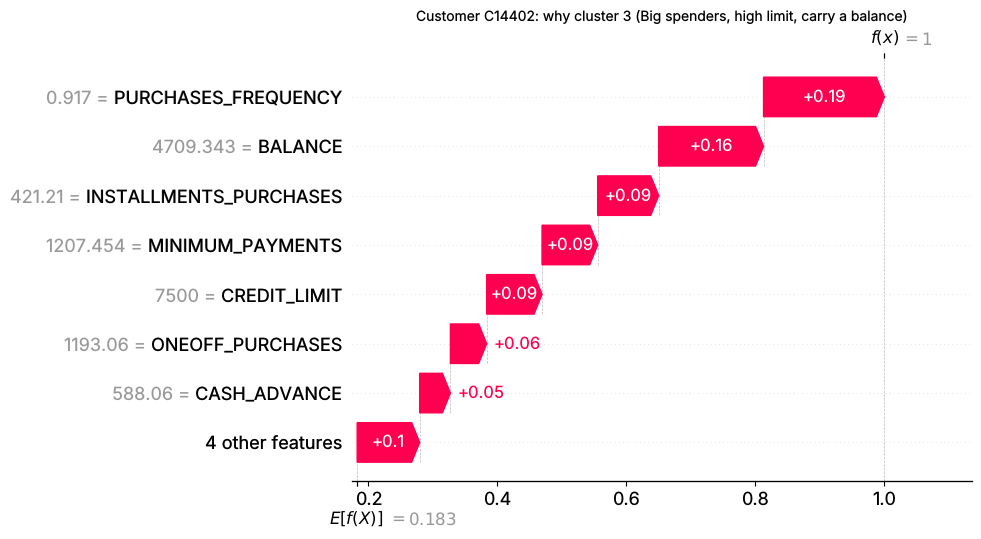

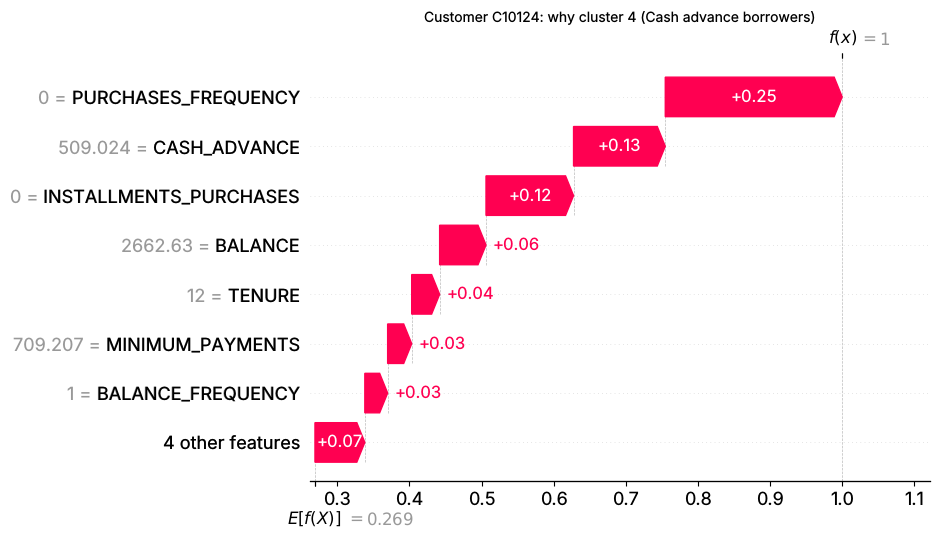

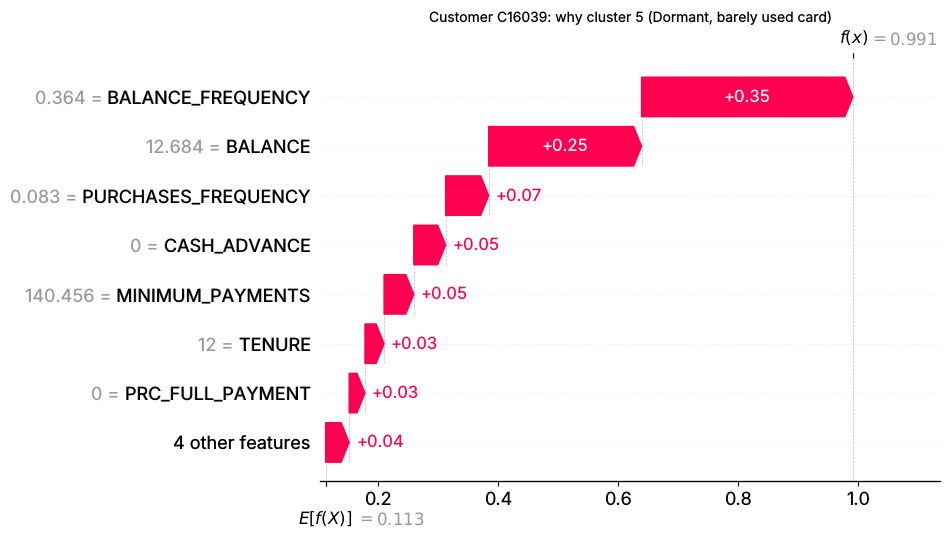

In [49]:
# Distance of each test customer to their own cluster centre, in the scaled space KMeans used
test_scaled = scaled.loc[X_test.index]
own_centres = kmeans_model.cluster_centers_[y_test.values]
distance_to_own_centre = pd.Series(np.linalg.norm(test_scaled.values - own_centres, axis=1), index=X_test.index)

for cluster in sorted(cluster_names):
    # the most typical member: the customer closest to the centre of their own cluster
    typical_customer = distance_to_own_centre[y_test == cluster].idxmin()
    row_position = X_test.index.get_loc(typical_customer)
    plt.figure()
    shap.plots.waterfall(shap_values[row_position, :, cluster], max_display=8, show=False)
    plt.title(f"Customer {typical_customer}: why cluster {cluster} ({cluster_names[cluster]})", fontsize=10)
    plt.savefig(FIGURES_DIR / f"shap_waterfall_cluster{cluster}.png", dpi=110, bbox_inches="tight")
    plt.show()

### What SHAP tells us

- **Global:** the features that move predictions most are `PURCHASES_FREQUENCY` (mean absolute SHAP 0.35), `CASH_ADVANCE` (0.30), `PRC_FULL_PAYMENT` (0.29) and `BALANCE` (0.26). `ONEOFF_PURCHASES` matters least (0.08): once we know *how often* someone buys, the size of their one-off purchases adds little.
- **Each cluster has its own signature feature:**
  - *Newer customers:* `TENURE` (0.09, versus about 0.03 or less for every other cluster).
  - *Frequent buyers, pay in full:* `PRC_FULL_PAYMENT` (0.14, the largest single value in their column).
  - *Dormant:* `BALANCE_FREQUENCY` and `BALANCE`.
  - *Cash advance borrowers:* `PURCHASES_FREQUENCY` (0.15), `CASH_ADVANCE` (0.11) and `INSTALLMENTS_PURCHASES` (0.09): no buying, but cash advances.
  - *Steady everyday spenders:* `CASH_ADVANCE` (the absence of it) and `PRC_FULL_PAYMENT`.
- **Waterfall plots, one typical customer per cluster** (the customer closest to the cluster centre). In every case the surrogate is 97% to 100% sure of the cluster, and the top drivers agree with the profile from Step 8:

| Cluster | Customer | Main drivers (feature value, push towards the cluster) |
|---|---|---|
| 0 Newer | C10816 | `TENURE` of 8 months (+0.63) |
| 1 Steady | C18632 | no `CASH_ADVANCE` (+0.16), `PRC_FULL_PAYMENT` of 0 (+0.11), balance 1,158 (+0.09) |
| 2 Pay in full | C14620 | `PRC_FULL_PAYMENT` of 0.75 (+0.47) |
| 3 Big spenders | C14402 | purchase frequency 0.92 (+0.19), balance 4,709 (+0.16), installments 421 (+0.09) |
| 4 Cash advance | C10124 | purchase frequency 0 (+0.25), cash advance 509 (+0.13), no installments (+0.12) |
| 5 Dormant | C16039 | `BALANCE_FREQUENCY` of 0.36 (+0.35), balance of 13 (+0.25) |

SHAP values here are in probability units, so "+0.47" means that feature alone added 47 percentage points to the probability of that cluster.

### 3. Distance contributions (direct explanation of KMeans)

KMeans puts each customer in the cluster whose centre is closest. The squared distance to a centre is the sum, over all 11 features, of (customer value minus centre value) squared. So we can split that distance **per feature**.

For each customer we compute, for every feature:

> **advantage = (squared gap to the nearest *other* centre) minus (squared gap to their *own* centre)**

A **positive** advantage means this feature makes the customer look more like their own cluster than like the runner-up. A **negative** one means this feature actually pulls them towards the other cluster. Adding up all 11 advantages gives the total reason the customer was assigned where they were. We average these by cluster.

**What this cell does:** Computes per-feature distance contributions for every customer and averages the advantage by cluster.  
**What to look for:** The sign check at the top (the smallest total advantage should be 0 or above) and the biggest positive values in each row of the table.  
**What the output means:** Large positive numbers show the features that really hold each cluster together. A feature that is near 0 does not help separate that cluster from its neighbour.

In [50]:
centres = kmeans_model.cluster_centers_                         # shape (6 clusters, 11 features)
customer_values = scaled.values                                 # shape (8950, 11)
own_cluster = labels.loc[scaled.index].values

# Squared gap to every centre, feature by feature: shape (customers, clusters, features)
squared_gap = (customer_values[:, None, :] - centres[None, :, :]) ** 2
total_distance = squared_gap.sum(axis=2)                        # squared distance to each centre

# Find each customer's nearest OTHER centre by hiding their own with infinity
distance_to_others = total_distance.copy()
distance_to_others[np.arange(len(scaled)), own_cluster] = np.inf
nearest_other = distance_to_others.argmin(axis=1)

rows = np.arange(len(scaled))
advantage = squared_gap[rows, nearest_other, :] - squared_gap[rows, own_cluster, :]  # (customers, features)
print(f"{advantage.sum(axis=1).min()=:.4f}  (should be 0 or above: every customer is nearest to their own centre)")

advantage_by_cluster = pd.DataFrame(advantage, columns=features, index=scaled.index).groupby(own_cluster).mean()
advantage_by_cluster.index = [f"{c}: {cluster_names[c]}" for c in advantage_by_cluster.index]
advantage_by_cluster.round(2)

advantage.sum(axis=1).min()=0.0031  (should be 0 or above: every customer is nearest to their own centre)


,BALANCE,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,BALANCE_FREQUENCY,PURCHASES_FREQUENCY,PRC_FULL_PAYMENT,TENURE
"0: Newer customers, small limit, mixed use",-0.40,0.00,-0.39,-0.36,0.28,0.14,-0.05,-0.25,-0.62,-0.62,12.20
1: Steady everyday spenders,0.02,0.30,-0.11,0.99,0.90,0.29,0.10,0.40,-0.20,0.88,0.03
"2: Frequent buyers, pay in full",0.54,-0.26,0.20,0.25,0.08,0.10,0.60,-0.23,0.20,5.61,-0.15
"3: Big spenders, high limit, carry a balance",0.56,0.75,0.71,0.16,1.36,0.72,0.64,0.01,0.72,0.01,-0.07
4: Cash advance borrowers,0.19,0.82,2.15,1.67,-0.38,-0.05,-0.07,-0.11,2.48,-0.01,-0.02
"5: Dormant, barely used card",2.42,0.11,0.09,-0.26,0.02,0.52,0.77,6.08,0.62,-0.18,-0.10


**What this cell does:** Draws the distance-contribution table as a heatmap.  
**What to look for:** Dark red cells: the feature strongly pulls members towards their own cluster. Blue cells: it pulls them towards the neighbouring cluster.  
**What the output means:** Compare with the SHAP importances. They answer slightly different questions (SHAP: what predicts the cluster; distance: what makes members close to their own centre), so agreement between them makes the story stronger.

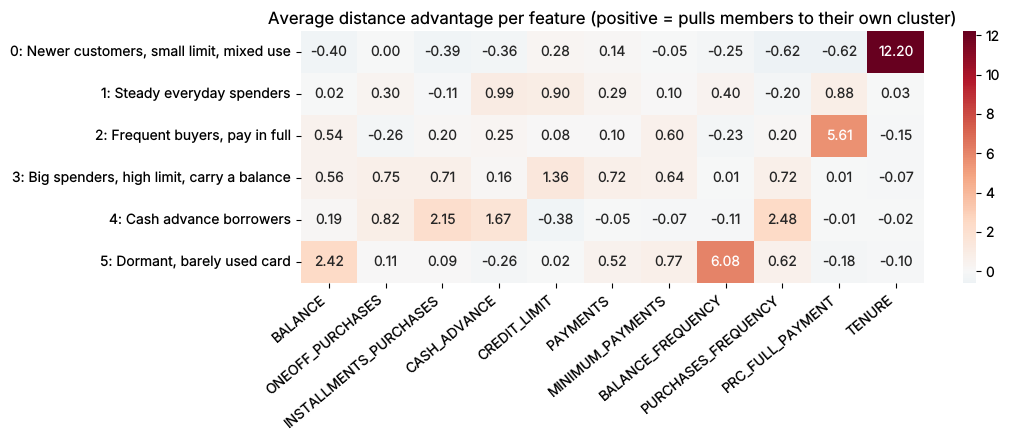

In [51]:
plt.figure(figsize=(11, 4.5))
sns.heatmap(advantage_by_cluster, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Average distance advantage per feature (positive = pulls members to their own cluster)")
plt.xticks(rotation=40, ha="right"); plt.tight_layout()
plt.savefig(FIGURES_DIR / "distance_contributions.png", dpi=110, bbox_inches="tight")
plt.show()

### What the distance contributions tell us

The biggest positive numbers in each row are the features that hold the cluster together. They match SHAP almost one for one:

- **Newer customers:** `TENURE` at **12.2**, by far the largest number in the table. On nearly every other feature these customers are closer to their neighbour, the cash advance cluster (negative values for spending, cash advance and payments). In practice this cluster is a **tenure group first** and a spending group second.
- **Frequent buyers, pay in full:** `PRC_FULL_PAYMENT` at **5.6**.
- **Dormant:** `BALANCE_FREQUENCY` at **6.1** and `BALANCE` at **2.4**.
- **Cash advance borrowers:** `PURCHASES_FREQUENCY` (2.5), `INSTALLMENTS_PURCHASES` (2.2) and `CASH_ADVANCE` (1.7).
- **Big spenders:** the pull is spread over many features at once (`CREDIT_LIMIT` 1.4, `ONEOFF_PURCHASES` 0.8, `PAYMENTS` 0.7, `PURCHASES_FREQUENCY` 0.7, `INSTALLMENTS_PURCHASES` 0.7). They are defined by a combination, not by one feature.
- **Steady everyday spenders:** no feature is above 1.0 (`CASH_ADVANCE` 1.0, `CREDIT_LIMIT` 0.9, `PRC_FULL_PAYMENT` 0.9). This is the most "ordinary" group. It is also the nearest neighbour for four of the other five clusters, so it sits in the middle of the map, which fits the 17 big spenders that the surrogate mistook for it.

### 4. Permutation importance (cross-check on SHAP)

Permutation importance shuffles one feature's values among the **test** customers, which breaks its link to the cluster, and measures how much accuracy falls. A big drop means the surrogate relied on that feature. A weakness: if two features carry the same information, shuffling one can look harmless because the other still covers for it, so correlated features can be understated.

**What this cell does:** Computes permutation importance on the test set (10 shuffles per feature) and puts it beside the SHAP ranking.  
**What to look for:** Whether the order of features is broadly the same in both columns, and the rank correlation at the bottom.  
**What the output means:** If two quite different methods give a similar ranking, we can trust the ranking more. Differences are worth a closer look, often because of correlated features.

In [52]:
from scipy.stats import spearmanr  # rank correlation to compare two importance rankings
from sklearn.inspection import permutation_importance  # shuffles one feature at a time to see how much accuracy drops

permutation = permutation_importance(surrogate, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE, scoring="accuracy", n_jobs=-1)
importance_table = pd.DataFrame({
    "permutation_drop_in_accuracy": permutation.importances_mean,   # average accuracy lost when this feature is shuffled
    "permutation_std": permutation.importances_std,
    "mean_abs_SHAP": mean_abs_shap["ALL CLUSTERS"],
}, index=features).sort_values("permutation_drop_in_accuracy", ascending=False)
importance_table["rank_permutation"] = importance_table["permutation_drop_in_accuracy"].rank(ascending=False).astype(int)
importance_table["rank_SHAP"] = importance_table["mean_abs_SHAP"].rank(ascending=False).astype(int)
display(importance_table.round(3))
rho = spearmanr(importance_table["permutation_drop_in_accuracy"], importance_table["mean_abs_SHAP"]).statistic
print(f"Rank agreement between permutation importance and SHAP (Spearman): {rho:.2f}")

,permutation_drop_in_accuracy,permutation_std,mean_abs_SHAP,rank_permutation,rank_SHAP
PURCHASES_FREQUENCY,0.172,0.005,0.352,1,1
PRC_FULL_PAYMENT,0.141,0.006,0.286,2,3
CASH_ADVANCE,0.112,0.004,0.304,3,2
TENURE,0.101,0.003,0.182,4,7
BALANCE_FREQUENCY,0.084,0.004,0.200,5,6
BALANCE,0.061,0.003,0.262,6,4
CREDIT_LIMIT,0.044,0.005,0.133,7,9
INSTALLMENTS_PURCHASES,0.044,0.002,0.204,8,5
PAYMENTS,0.026,0.003,0.121,9,10
MINIMUM_PAYMENTS,0.020,0.002,0.156,10,8


Rank agreement between permutation importance and SHAP (Spearman): 0.85


### What permutation importance tells us

- **The two methods agree on the ranking** (Spearman 0.85, where 1 is identical order). Both put `PURCHASES_FREQUENCY` first (shuffling it costs 17.2 points of accuracy) and `ONEOFF_PURCHASES` last (1.8 points). `PRC_FULL_PAYMENT` and `CASH_ADVANCE` take places 2 and 3 in both.
- **Where they differ:** `TENURE` is 4th for permutation (10.1 points) but 7th for SHAP. Shuffling tenure creates customers with the wrong tenure, and the surrogate sends many of them to the newer-customer cluster, so the accuracy drop is large even though only one cluster depends on it. `INSTALLMENTS_PURCHASES` goes the other way (8th versus 5th), most likely because `PURCHASES_FREQUENCY` is correlated with it and can cover for it when it is shuffled. This is the weakness of permutation importance with correlated features, noted above.

### Limitations of these explanations

- They describe **the clusters KMeans produced** and **what the surrogate learned about them**. They are not a ground truth about why customers behave as they do, and they do not show cause and effect.
- **Fidelity:** the surrogate matches KMeans on 95.0% of unseen customers. For the other 5%, the explanations may describe a different cluster than the one the customer is actually in.
- **Correlated features** (for example purchase frequency and installment purchases) can share credit with each other in SHAP and hide each other in permutation importance, so single-feature rankings should not be over-read.
- The explanations rely on the feature set, the transform, and the choice of k=6 made earlier. If any of them changed, the explanations would change too (in notebook 03, between 3% and 17% of customers changed group under the alternative preprocessing choices we tried, the largest effect coming from reshaping the bounded columns).

---
# Part 5: Conclusions and deliverables
*Step 10. The text below is the same as `reports/business_summary.md`, which is the file to share.*

## Summary

We grouped 8,950 credit card holders into six segments, using how they spend, pay and borrow over six months. The groups are stable: they come back almost unchanged when we resample customers. A separate model can also recover each customer's segment from their numbers 95% of the time. The boundaries between neighbouring segments are soft, because customers form a continuous range and not six islands.

| Segment | Share | What they do | What they likely need |
|---|---|---|---|
| Cash advance borrowers | 27% | Almost no purchases, a carried balance and the largest cash advances | A risk and exposure review. Cash advances usually cost more, so test an offer that moves this borrowing to a cheaper product. |
| Steady everyday spenders | 23% | Regular, moderate purchases on a small limit, a carried balance, no cash advances | Usage nudges, payment reminders, and a modest limit increase for those who pay on time. |
| Big spenders, high limit, carry a balance | 18% | Highest spending, balance and limit (about 7,000), and they borrow too | A credit limit review, retention offers and close monitoring. They carry the largest exposure. |
| Frequent buyers, pay in full | 14% | Buy almost every month and score high on the full-payment measure (median 0.80, versus 0.00 for most other segments) | Rewards and retention. Skip collections-style reminders. Consider higher limits. |
| Dormant, barely used card | 11% | Near-zero balance and rarely any activity | A reactivation campaign, or a decision on whether to keep the account open. |
| Newer customers, small limit, mixed use | 7% | About 7 months as customers, the smallest limits, a mix of small purchases and cash advances | Onboarding support. Re-check them after a year, because their behaviour is still forming. |

**What this analysis cannot tell us.** The data has no revenue, profit, late payment or default information, so we cannot say which segment earns the most or is the riskiest. Where the table says "exposure" or "likely need", that is a hypothesis from behaviour, not a measured result. It is a six-month snapshot, so it shows what customers did, not why, and not how they will change. The segments are associations, not causes. Any action should first be tested on a small group with a control group.

## Limitations

- **Sample size and source.** 8,950 customers from one unnamed card portfolio over six months. We do not know the bank, country, year or how customers were chosen, so the results may not carry over to another portfolio.
- **Missing data.** `MINIMUM_PAYMENTS` was missing for 313 customers (3.5%) and `CREDIT_LIMIT` for one. For 240 of the 313, payments were exactly zero, so the blank probably means "nothing due". We filled with the median. Filling those with 0 instead changed the groups only a little (agreement 0.90).
- **No ground truth.** There are no true customer types to compare with, so we can only use internal measures. Silhouette is about 0.22, which is low: the groups touch.
- **How stable the clusters are.** Resampling customers gave an agreement score of 0.976 for six segments (1 is identical). Our own choices also matter a little: dropping `MINIMUM_PAYMENTS` moves 6.5% of customers to a different segment, and swapping the log transform for another standard one (Yeo-Johnson) moves 3.5%. The choice that matters most is how the three bounded columns (tenure, balance frequency, share paid in full) are treated: reshaping them too moves 17.4% of customers.
- **A small number of odd rows.** About 14 rows (0.2%) break simple rules (for example purchases but zero purchase transactions). We kept them.
- **No data dictionary.** In 26% of customers the minimum payment is above the payments. We could not tell whether this is under-payment or a difference in how the columns are measured.
- **One segment is mostly about tenure.** The newer customers are separated mainly by having a short history, not only by how they use the card.

## Next steps: what data would make the model stronger

1. **Outcomes:** late payments, defaults and write-offs, to check which segments are actually risky.
2. **Revenue:** interest, fees and interchange income per customer, so segments can be ranked by profit.
3. **Time:** monthly figures instead of six-month totals, so we can see trends and segment migration (who moves from steady to dormant).
4. **Customer details:** age, income, region and product type, to describe segments in terms the business already uses.
5. **Campaign history:** which offers each customer received and how they responded, to test the recommendations above.
6. **A data dictionary** for the columns, especially the payment fields.


### Project files

- Business summary: `reports/business_summary.md`
- Profiling report: `reports/credit_card_profile.html`
- Figures and cluster profile tables: `reports/figures/`, `reports/cluster_profile_*.csv`
- Saved model, pipeline and labels: `data/processed/` (not stored in git)
- Step-by-step notebooks: `notebooks/01_eda.ipynb` to `04_explainability.ipynb`
